# Reasoning Agent: Knowledge Base → Representation → Classical Reasoning → True/False

**SECTIONS**

0. Settings
1. Imports
2. EDA: Exploring the public datasets
3. Input reader: any format → clean text (Unicode / ASCII / Prover9 / Prolog logic, English, headers, numbering)
4. Engine A: English facts + if/then rules → forward chaining with unification
5. Engine B: CounterBench-style (cause rules + "what if") → search + forward chaining
6. Engine C: First-order logic → Horn forward chaining, else CNF → grounding → DPLL refutation
7. Router: one entry point for every question
8. Sanity tests (every input style)
9. Load the public datasets
10. Final accuracy and inference time on the public datasets
11. Example reasoning traces
12. Create submission.csv (id, label)
13. **STANDALONE CELL**: runs alone on the private test file (all imports + all code in one cell)

---

**Pipeline for every question (context + statement):**
1. **CounterBench-style** text ("A causes B", "Would Y occur if…") → regex → cause rules → **search over unknown roots + forward chaining**
2. **Logic** in any common style → normalised to standard symbols → **FOL engine**
   - only facts + if-then rules (Horn) → **forward chaining with unification** (very fast)
   - anything else (or, xor, not, ∃) → **CNF + Skolemization + grounding + DPLL refutation**
3. **English facts + rules** (RuleTaker style, also "someone / they", "All X are Y", "not") → **forward chaining with unification**
4. Nothing can read it → **default answer False**


## 0. Settings

In [1]:
# ---- public datasets (used for development + accuracy) ----
RT_FILES = {"RuleTaker/train": "RuleTaker/train.csv",
            "RuleTaker/test":  "RuleTaker/test.csv",
            "RuleTaker/ood":   "RuleTaker/ood_test.csv"}
CB_FILES = {"CounterBench/alpha":    "CounterBench/data_balanced_alpha_V1.csv",
            "CounterBench/backdoor": "CounterBench/data_balanced_backdoor_V2.csv"}
FOLIO_FILES = {"FOLIO/train":      "FOLIO/train.csv",
               "FOLIO/validation": "FOLIO/validation.csv"}

# Evaluation is given as LOGIC, so for FOLIO we feed the logic columns
# (premises-FOL, conclusion-FOL). Set to "english" to see the plain-English result.
FOLIO_INPUT = "fol"

# ---- private test file ----
# Any of: .csv / .tsv / .json / .jsonl / .txt  (column names are detected automatically)
TEST_PATH       = "test_private.csv"
SUBMISSION_PATH = "submission.csv"

# ---- reasoning options ----
DEFAULT_ANSWER = False      # used only when no engine can read the question
NL_CLOSED_WORLD = True      # English rules: "X is not Y" is True when "X is Y" cannot be derived
DPLL_MAX_STEPS = 20000      # safety limit for the FOL search (keeps time low)
GROUND_LIMIT   = 300000     # safety limit for grounded clauses
CB_MAX_ROOTS   = 18         # safety limit for CounterBench search (2^18 worlds)


## 1. Imports

In [2]:
import os, re, sys, json, time, ast, math, itertools
from functools import lru_cache
import pandas as pd

sys.setrecursionlimit(10000)   # DPLL is recursive

def to_bool(x):
    return str(x).strip().lower() in ("true", "yes", "1", "entailed")


# 2. EDA: Exploring the public datasets
My exploration of RuleTaker, FOLIO and CounterBench (shapes, labels, sample data, charts).
These findings guided the design of the engines in the next sections.
If the dataset folders are not present, this whole section is skipped automatically.

In [3]:
# ===== EDA: settings (runs only if the public data folders exist) =====
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RUN_EDA = all(os.path.exists(p) for p in ["RuleTaker/train.csv", "FOLIO/train.csv",
                                         "CounterBench/data_balanced_alpha_V1.csv",
                                         "CounterBench/meta_model_alpha_V1.csv"])

## EDA 1: RuleTaker

In [4]:
# ===== EDA: RuleTaker – load data and show first rows (train) =====
if RUN_EDA:
    rt_train = pd.read_csv("RuleTaker/train.csv")
    rt_test = pd.read_csv("RuleTaker/test.csv")
    rt_ood = pd.read_csv("RuleTaker/ood_test.csv")

    print("Train.csv")
    display(rt_train.head())


Train.csv


,context,statement,reasoning,depth,flag
0,Facts:\nThe wall dances gracefully.\nThe river...,The sandwich dances gracefully.,Since we know that based on the river dances g...,2,False
1,Facts:\nCharlie is fast.\nStanford University ...,The river volunteers.,"Given that given that charlie is fast, it foll...",3,False
2,Facts:\nThe globe is colorful.\nThe globe is f...,Mike is colorful.,Applied Rule: since the fact that if the globe...,1,True
3,Facts:\nEmma enjoys music.\nEmma enjoys music....,Emma is a scientist.,"Given that if the mountain is a scientist, the...",3,True
4,Facts:\nEthan grows plants.\nThe plane explore...,The forest is happy.,Applied Rule: since the fact that when ethan g...,2,True


In [5]:
# ===== EDA: RuleTaker – first rows (test) =====
if RUN_EDA:
    print("Test.csv")
    display(rt_test.head())


Test.csv


,context,statement,reasoning,depth,flag
0,Facts:\nLiam volunteers.\nThe shop sings beaut...,The book volunteers.,"Since we know that assuming liam volunteers, w...",3,False
1,Facts:\nLucy is a scientist.\nLucy is a scient...,The sky is fluffy.,Since we know that assuming lucy is a scientis...,3,False
2,Facts:\nJack makes pizza.\nThe cloud fishes in...,Emma carries bags.,Applied Rule: since the fact that given that t...,3,False
3,Facts:\nAlice takes pictures.\nThe zoo is inte...,The zoo is fast.,"Given that based on the zoo is interesting, it...",3,False
4,Facts:\nHenry swims well.\nMike plays football...,The sun plays football.,Applied Rule: since the fact that given that m...,3,False


In [6]:
# ===== EDA: RuleTaker – first rows (OOD test) =====
if RUN_EDA:
    print("Ood Test.csv")
    display(rt_ood.head())


Ood Test.csv


,context,statement,reasoning,depth,flag
0,Facts:\nThe pumpkin solves puzzles.\nSarah is ...,The teacher plays instruments.,"Given that based on sarah is interesting, it i...",4,True
1,Facts:\nThe moon is a chef.\nThe moon is magic...,The fountain jumps high.,"Because when the moon is a chef, we can conclu...",4,False
2,Facts:\nThe pumpkin is quiet.\nAva rides bikes...,Ava hosts parties.,"Given that if ava is quiet, then the pumpkin i...",4,False
3,Facts:\nHenry reads books.\nSarah goes to the ...,Sarah carries bags.,"Since we know that if henry carries bags, then...",4,True
4,Facts:\nJack swims well.\nThe globe plays game...,Jack plays games.,"Since we know that based on jack swims well, i...",4,False


In [7]:
# ===== EDA: RuleTaker – one full example, every column =====
if RUN_EDA:
    index = 0
    col = list(rt_train.columns)

    for c in col:
        print(f"\n{c}:",rt_train.iloc[index][c])



context: Facts:
The wall dances gracefully.
The river dances gracefully.
The river becomes famous.
Rules:
Assuming the river dances gracefully, we can say the river is fast.
If the wall dances gracefully, then the wall dances gracefully.
Based on the river becomes famous, it is evident that the wall dances gracefully.
Assuming the river becomes famous, we can say the river becomes famous.
Assuming the sandwich dances gracefully, we can say the river is fast.
Given that the river is fast, it follows that the river is fast.

statement: The sandwich dances gracefully.

reasoning: Since we know that based on the river dances gracefully, it is evident that the river is fast, it follows that the river is fast.
Applying the logic of given that the wall dances gracefully, it follows that the wall dances gracefully, we deduce that the wall dances gracefully.
Because when the river becomes famous, we can conclude the wall dances gracefully, we can conclude that the wall dances gracefully.
Becau

In [8]:
# ===== EDA: RuleTaker – shape of each split =====
if RUN_EDA:
    print("Train = ", rt_train.shape)
    print("Test = ",rt_test.shape)
    print("OOD Test = ",rt_ood.shape)


Train =  (1000, 5)
Test =  (250, 5)
OOD Test =  (375, 5)


In [9]:
# ===== EDA: RuleTaker – missing values =====
if RUN_EDA:
    print("Train:")
    print(rt_train.isnull().sum())

    print("\nTest:")
    print(rt_test.isnull().sum())

    print("\nOOD Test:")
    print(rt_ood.isnull().sum())


Train:
context      0
statement    0
reasoning    0
depth        0
flag         0
dtype: int64

Test:
context      0
statement    0
reasoning    0
depth        0
flag         0
dtype: int64

OOD Test:
context      0
statement    0
reasoning    0
depth        0
flag         0
dtype: int64


In [10]:
# ===== EDA: RuleTaker – label (flag) counts =====
if RUN_EDA:
    print("Train:")
    print(rt_train['flag'].value_counts())

    print("\nTest:")
    print(rt_test['flag'].value_counts())

    print("\nOOD Test:")
    print(rt_ood['flag'].value_counts())


Train:
flag
True     594
False    406
Name: count, dtype: int64

Test:
flag
True     156
False     94
Name: count, dtype: int64

OOD Test:
flag
False    244
True     131
Name: count, dtype: int64


In [11]:
# ===== EDA: RuleTaker – helper: count facts and rules in a context =====
if RUN_EDA:
    def context_info(ctx):
        facts, rules= ctx.split("Rules:")
        x = ["Facts:" in i for i in ctx]
        if "False" not in x:
            f = len([s.strip() for s in facts.replace("Facts:", " ").split("\n") if s.strip()])
        else: 
            f=0
        x = ["Rules:" in i for i in ctx]
        if "False" not in x:
            r = len([s.strip() for s in rules.split("\n") if s.strip()])
        else: 
            r=0
        return f, r


Train Data : 

Min Facts :  3
Max Facts :  3
Min Rules :  5
Max Rules :  10


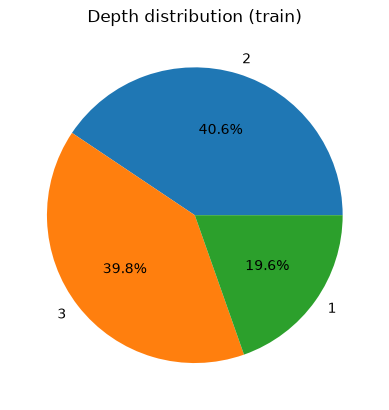

Test Data : 

Min Facts :  3
Max Facts :  3
Min Rules :  5
Max Rules :  10


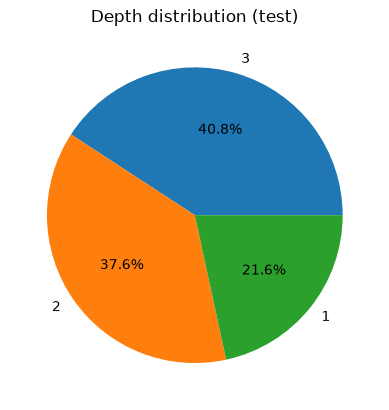

Ood Test Data : 

Min Facts :  3
Max Facts :  3
Min Rules :  5
Max Rules :  10


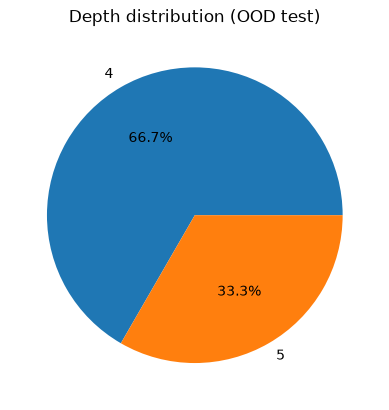

In [12]:
# ===== EDA: RuleTaker – facts/rules per context + depth distribution =====
if RUN_EDA:
    print("Train Data : \n")
    cxt_info = rt_train["context"].apply(context_info).tolist()

    print("Min Facts : ", min([i[0] for i in cxt_info]))
    print("Max Facts : ",max([i[0] for i in cxt_info]))
    print("Min Rules : ",min([i[1] for i in cxt_info]))
    print("Max Rules : ",max([i[1] for i in cxt_info]))

    plt.pie(rt_train["depth"].value_counts(), labels=rt_train["depth"].value_counts().index, autopct="%1.1f%%")
    plt.title("Depth distribution (train)")
    plt.show()

    print("Test Data : \n")
    cxt_info = rt_test["context"].apply(context_info).tolist()

    print("Min Facts : ", min([i[0] for i in cxt_info]))
    print("Max Facts : ",max([i[0] for i in cxt_info]))
    print("Min Rules : ",min([i[1] for i in cxt_info]))
    print("Max Rules : ",max([i[1] for i in cxt_info]))

    plt.pie(rt_test["depth"].value_counts(), labels=rt_test["depth"].value_counts().index, autopct="%1.1f%%")
    plt.title("Depth distribution (test)")
    plt.show()

    print("Ood Test Data : \n")
    cxt_info = rt_ood["context"].apply(context_info).tolist()

    print("Min Facts : ", min([i[0] for i in cxt_info]))
    print("Max Facts : ",max([i[0] for i in cxt_info]))
    print("Min Rules : ",min([i[1] for i in cxt_info]))
    print("Max Rules : ",max([i[1] for i in cxt_info]))

    plt.pie(rt_ood["depth"].value_counts(), labels=rt_ood["depth"].value_counts().index, autopct="%1.1f%%")
    plt.title("Depth distribution (OOD test)")
    plt.show()


In [13]:
# ===== EDA: RuleTaker – duplicate rows =====
if RUN_EDA:
    print(rt_train.duplicated().sum())
    print(rt_test.duplicated().sum())
    print(rt_ood.duplicated().sum())


0
0
0


In [14]:
# ===== EDA: RuleTaker – check for variable words (someone/they/it...) in train =====
if RUN_EDA:
    words = ["someone", "something", "they", "it", "everyone", "everything", "all"]

    for i in  range(rt_train.shape[0]):
        emp = []
        for ctx in rt_train[['context', 'statement']].iloc[i]['context'].replace("\n"," ").lower().split(" "):
            for w in words:
                if w == ctx:
                    emp.append(w)
        if len(emp)!=0:
            print(emp)
            # print(rt_train.iloc[i]['context'])
            # print(rt_train.iloc[i]['statement'],"\n")


['it', 'it']
['it', 'it', 'it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it']
['it']
['it', 'it', 'it', 'it', 'it']
['it']
['it', 'it', 'it', 'it', 'it']
['it', 'it', 'it', 'it', 'it']
['it', 'it', 'it']
['it', 'it']
['it', 'it']
['it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it']
['it', 'it']
['it']
['it', 'it']
['it', 'it', 'it']
['it']
['it', 'it', 'it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it']
['it', 'it', 'it']
['it', 'it']
['it']
['it', 'it', 'it']
['it', 'it']
['it', 'it', 'it', 'it', 'it', 'it']
['it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it', 'it']
['it']
['it', 'it']
['it', 'it', 'it', 'it', 'it', 'it']
['it', 'it', 'it']
['it']
['it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it', 'it', 'it']
['it', 'it']
['it']
['it', 'it', 'it', 'it']
['it', 'it', 'it']
['it', 'it',

In [15]:
# ===== EDA: RuleTaker – check for variable words in test =====
if RUN_EDA:
    words = ["someone", "something", "they", "it", "everyone", "everything", "all"]

    for i in  range(rt_test.shape[0]):
        emp = []
        for ctx in rt_test[['context', 'statement']].iloc[i]['context'].replace("\n"," ").lower().split(" "):
            for w in words:
                if w == ctx:
                    emp.append(w)
        if len(emp)!=0:
            print(emp)
            # print(rt_train.iloc[i]['context'])
            # print(rt_train.iloc[i]['statement'],"\n")


['it', 'it', 'it', 'it']
['it']
['it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it']
['it']
['it', 'it', 'it', 'it']
['it', 'it', 'it']
['it']
['it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it']
['it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it']
['it', 'it', 'it']
['it', 'it', 'it', 'it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it']
['it', 'it', 'it', 'it']
['it', 'it']
['it', 'it', 'it', 'it']
['it', 'it']
['it']
['it', 'it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it']
['it', 'it']
['it']
['it', 'it']
['it', 'it', 'it', 'it']
['it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it', 'it', 'it', 'it', 'it']
['it', 'it', 'it', 'it']
['it', 'it', 'it']
['it', 'it']
['it', 'it']
['it', 'it', 'it', 'it', 'it', 'it']
['it']
['it', 'it']
['it', 'it', 'it']
['it', 'it', 'it']
['it']
['it']
['it']
['it', 'it', 'it', 'it', 'i

## EDA 2: FOLIO

In [16]:
# ===== EDA: FOLIO – load data and show first rows (train) =====
if RUN_EDA:
    f_train = pd.read_csv("FOLIO/train.csv")
    f_val = pd.read_csv("FOLIO/validation.csv")

    print("Train.csv")
    display(f_train.head())


Train.csv


,story_id,premises,premises-FOL,conclusion,conclusion-FOL,label,example_id
0,406,All people who regularly drink coffee are depe...,"∀x (DrinkRegularly(x, coffee) → IsDependentOn(...",Rina doesn't want to be addicted to caffeine o...,"¬WantToBeAddictedTo(rina, caffeine) ∨ (¬AwareT...",True,1126
1,406,All people who regularly drink coffee are depe...,"∀x (DrinkRegularly(x, coffee) → IsDependentOn(...",Rina eith doesn't want to be addicted to caffe...,"¬WantToBeAddictedTo(rina, caffeine) ⊕ ¬AwareTh...",True,1127
2,406,All people who regularly drink coffee are depe...,"∀x (DrinkRegularly(x, coffee) → IsDependentOn(...",Rina either regularly drinks coffee or is unaw...,"DrinkRegularly(rina, coffee) ⊕ IsUnawareThatC...",False,1128
3,406,All people who regularly drink coffee are depe...,"∀x (DrinkRegularly(x, coffee) → IsDependentOn(...",If Rina either doesn't want to be addicted to ...,(DoNotWantToBeAddictedToCaffeine(rina) ⊕ ¬Awar...,True,1129
4,8,Miroslav Venhoda was a Czech choral conductor ...,Czech(miroslav) ∧ ChoralConductor(miroslav) ∧ ...,Miroslav Venhoda loved music.,"Love(miroslav, music)",Uncertain,20


In [17]:
# ===== EDA: FOLIO – first rows (validation) =====
if RUN_EDA:
    print("Validation.csv")
    display(f_val.head())


Validation.csv


,story_id,premises,premises-FOL,conclusion,conclusion-FOL,label,example_id
0,380,People in this club who perform in school tale...,"∀x (InThisClub(x) ∧ PerformOftenIn(x, schoolTa...",Bonnie performs in school talent shows often.,"InThisClub(bonnie) ∧ (Perform(bonnie, schoolTa...",Uncertain,1014
1,380,People in this club who perform in school tale...,"∀x (InThisClub(x) ∧ PerformOftenIn(x, schoolTa...",If Bonnie is either both a young child or teen...,¬((YoungChildren(bonnie) ⊕ Teenager(bonnie)) ∧...,True,1015
2,380,People in this club who perform in school tale...,"∀x (InThisClub(x) ∧ PerformOftenIn(x, schoolTa...",If Bonnie either chaperones high school dances...,"(Chaperone(bonnie, highSchoolDance) ⊕ Perform(...",False,1016
3,426,All employees who schedule a meeting with thei...,"∀x ((Employee(x) ∧ Schedule(x, meeting, custom...",James has lunch in the company.,"HasLunch(james, company)",Uncertain,1208
4,426,All employees who schedule a meeting with thei...,"∀x ((Employee(x) ∧ Schedule(x, meeting, custom...",James does not have lunch in the company.,"¬HasLunch(james, company)",Uncertain,1209


In [18]:
# ===== EDA: FOLIO – two full examples, every column =====
if RUN_EDA:
    index = 0
    col = list(f_train.columns)

    for c in col:
        print(f"\n{c}:",f_train.iloc[index][c])

    print("\n")
    index = 1
    for c in col:
        print(f"\n{c}:",f_train.iloc[index][c])



story_id: 406

premises: All people who regularly drink coffee are dependent on caffeine.
People regularly drink coffee, or they don't want to be addicted to caffeine, or both.
No one who doesn't want to be addicted to caffeine is unaware that caffeine is a drug.
Rina is either a student who is unaware that caffeine is a drug, or she is not a student and is she aware that caffeine is a drug.
Rina  is either a student who is dependent on caffeine, or she is not a student and not dependent on caffeine.

premises-FOL: ∀x (DrinkRegularly(x, coffee) → IsDependentOn(x, caffeine))
∀x (DrinkRegularly(x, coffee)  ∨ (¬WantToBeAddictedTo(x, caffeine)))
∀x (¬WantToBeAddictedTo(x, caffeine) → ¬AwareThatDrug(x, caffeine))
¬(Student(rina) ⊕  ¬AwareThatDrug(rina, caffeine))
¬(IsDependentOn(rina, caffeine) ⊕ Student(rina))

conclusion: Rina doesn't want to be addicted to caffeine or is unaware that caffeine is a drug.

conclusion-FOL: ¬WantToBeAddictedTo(rina, caffeine) ∨ (¬AwareThatDrug(rina, caffein

In [19]:
# ===== EDA: FOLIO – label counts =====
if RUN_EDA:
    print(f_train['label'].value_counts())
    print(f_val['label'].value_counts())


label
True         388
Uncertain    324
False        289
Name: count, dtype: int64
label
True         72
Uncertain    69
False        62
Name: count, dtype: int64


In [20]:
# ===== EDA: FOLIO – shape (train) =====
if RUN_EDA:
    display(f_train.shape)


(1001, 7)

In [21]:
# ===== EDA: FOLIO – stories in train (questions per story) =====
if RUN_EDA:
    print("Total Unique Stories = ", len(f_train['story_id'].unique()))
    print(f_train['story_id'].value_counts())


Total Unique Stories =  340
story_id
391    10
401    10
316    10
408     9
333     9
       ..
300     1
240     1
286     1
275     1
303     1
Name: count, Length: 340, dtype: int64


In [22]:
# ===== EDA: FOLIO – premises of one story (story 391) =====
if RUN_EDA:
    for i in f_train[f_train["story_id"] == 391]["premises"]:
        print(i, "\n")


All imaginative processes that Dan knows are results of creative processes.
All science fiction that Dan knows comes from an imaginative process.
Everthing that Dan knows comes from either science-fiction or realistic fiction.
No facts that Dan knows have proven to be false.
Dan knows that Dune is science fiction or has proven to be false. 

All imaginative processes that Dan knows are results of creative processes.
All science fiction that Dan knows comes from an imaginative process.
Everthing that Dan knows comes from either science-fiction or realistic fiction.
No facts that Dan knows have proven to be false.
Dan knows that Dune is science fiction or has proven to be false. 

All imaginative processes that Dan knows are results of creative processes.
All science fiction that Dan knows comes from an imaginative process.
Everthing that Dan knows comes from either science-fiction or realistic fiction.
No facts that Dan knows have proven to be false.
Dan knows that Dune is science ficti

In [23]:
# ===== EDA: FOLIO – shape (validation) =====
if RUN_EDA:
    display(f_val.shape)


(203, 7)

In [24]:
# ===== EDA: FOLIO – stories in validation =====
if RUN_EDA:
    print("Total Unique Stories = ", len(f_val['story_id'].unique()))
    print(f_val['story_id'].value_counts())


Total Unique Stories =  73
story_id
471    5
319    5
483    5
456    5
101    5
      ..
295    1
258    1
292    1
259    1
280    1
Name: count, Length: 73, dtype: int64


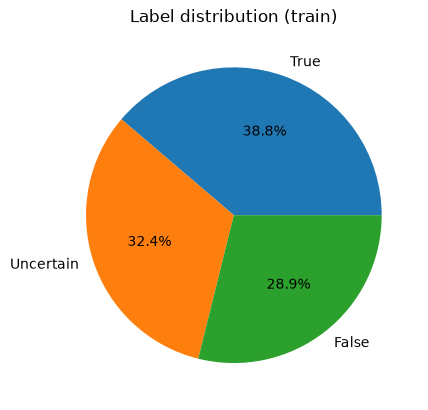

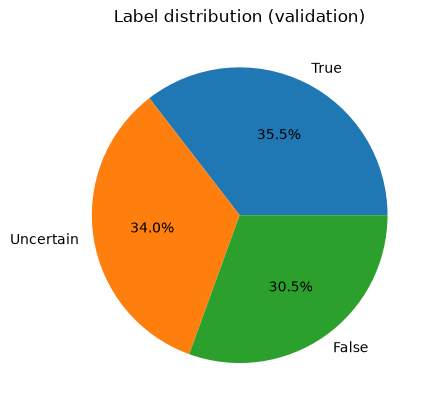

In [25]:
# ===== EDA: FOLIO – label distribution pie charts =====
if RUN_EDA:
    plt.pie(f_train["label"].value_counts(), labels=f_train["label"].value_counts().index, autopct="%1.1f%%")
    plt.title("Label distribution (train)")
    plt.show()

    plt.pie(f_val["label"].value_counts(), labels=f_val["label"].value_counts().index, autopct="%1.1f%%")
    plt.title("Label distribution (validation)")
    plt.show()


## EDA 3: CounterBench

- question_id: It represents a unique identifier for each question within the file
- given_info: It contains supplementary background or contextual information, expressed in natural language, that the model may need in order to provide a more accurate and well-informed answer to the question.
- question: It stores the specific question being asked, also formulated in natural language. Combined with the content in given_info, it will generate the whole sentence for querying.
- answer: It is designated for the response to the question, (Yes and No)
- type: The counterfactual type of questions, There are four values: Basic, Conditional, Joint, and Nested. Each type implies different assumptions and levels of reasoning depth.
- meta: metadata about the question associated with the question

In [26]:
# ===== EDA: CounterBench – load data and meta files =====
if RUN_EDA:
    cb_data_balanced_alpha_v1 = pd.read_csv("CounterBench/data_balanced_alpha_V1.csv")
    cb_meta_model_alpha_V1 = pd.read_csv("CounterBench/meta_model_alpha_V1.csv")
    cb_data_balanced_backdoor_V2 = pd.read_csv("CounterBench/data_balanced_backdoor_V2.csv")
    cb_meta_model_backdoor_V2 = pd.read_csv("CounterBench/meta_model_backdoor_V2.csv")


In [27]:
# ===== EDA: CounterBench – first rows (alpha) =====
if RUN_EDA:
    display(cb_data_balanced_alpha_v1.head())


,question,given_info,answer,type,question_id,meta.story_id,meta.rung,meta.query_type,meta.model_id,meta.graph_id
0,Would Lumbo occur if not Ziklo instead of Ziklo?,"We know that Ziklo causes Blaf, Blaf causes Tr...",no,basic,0,nonsense_0,3,det-counterfactual,0,graph5
1,Would Zlim occur if not Glent instead of Glent?,"We know that Glent causes Razz, Razz causes Pe...",no,basic,200,nonsense_1,3,det-counterfactual,1,graph5
2,Would Klep occur if not Praf instead of Praf?,"We know that Praf causes Vank, Vank causes Scu...",no,basic,400,nonsense_2,3,det-counterfactual,2,graph5
3,Would Jext occur if not Fizo instead of Fizo?,"We know that Fizo causes Blorn, Blorn causes P...",no,basic,600,nonsense_3,3,det-counterfactual,3,graph5
4,Would Wrox occur if not Nuv instead of Nuv?,"We know that Nuv causes Splee, Splee causes Bl...",no,basic,800,nonsense_4,3,det-counterfactual,4,graph5


In [28]:
# ===== EDA: CounterBench – meta model (alpha) =====
if RUN_EDA:
    display(cb_meta_model_alpha_V1.head())


,model_id,background,nonsense,variable_mapping.X,variable_mapping.V1,variable_mapping.V2,variable_mapping.V3,variable_mapping.V4,variable_mapping.V5,variable_mapping.V6,variable_mapping.V7,variable_mapping.V8,variable_mapping.Y
0,0,"Imagine a self-contained, hypothetical world w...",True,Ziklo,Blaf,Trune,Vork,Sline,Frim,Qado,Jurf,Drig,Lumbo
1,1,"Imagine a self-contained, hypothetical world w...",True,Glent,Razz,Pex,Zurn,Melf,Crip,Flen,Tork,Bilo,Zlim
2,2,"Imagine a self-contained, hypothetical world w...",True,Praf,Vank,Scud,Wrenk,Yobb,Glim,Spog,Torb,Frun,Klep
3,3,"Imagine a self-contained, hypothetical world w...",True,Fizo,Blorn,Plim,Quaz,Skul,Triv,Yex,Rild,Vurn,Jext
4,4,"Imagine a self-contained, hypothetical world w...",True,Nuv,Splee,Blen,Druk,Plog,Skrim,Zimb,Yurd,Grif,Wrox


In [29]:
# ===== EDA: CounterBench – first rows (backdoor) =====
if RUN_EDA:
    display(cb_data_balanced_backdoor_V2.head())


,question,given_info,answer,type,question_id,meta.story_id,meta.rung,meta.query_type,meta.model_id,meta.graph_id
0,Would Lumbo occur if not Ziklo instead of Ziklo?,"We know that Blaf causes Ziklo, Ziklo or Blaf ...",yes,backdoor,0,nonsense_0,3,det-counterfactual,0,graph5
1,Would Zlim occur if not Glent instead of Glent?,"We know that Razz causes Glent, Glent or Razz ...",yes,backdoor,200,nonsense_1,3,det-counterfactual,1,graph5
2,Would Klep occur if not Praf instead of Praf?,"We know that Vank causes Praf, Praf or Vank ca...",yes,backdoor,400,nonsense_2,3,det-counterfactual,2,graph5
3,Would Jext occur if not Fizo instead of Fizo?,"We know that Blorn causes Fizo, Fizo or Blorn ...",yes,backdoor,600,nonsense_3,3,det-counterfactual,3,graph5
4,Would Wrox occur if not Nuv instead of Nuv?,"We know that Splee causes Nuv, Nuv or Splee ca...",yes,backdoor,800,nonsense_4,3,det-counterfactual,4,graph5


In [30]:
# ===== EDA: CounterBench – meta model (backdoor) =====
if RUN_EDA:
    display(cb_meta_model_backdoor_V2.head())


,model_id,background,nonsense,variable_mapping.X,variable_mapping.V1,variable_mapping.V2,variable_mapping.V3,variable_mapping.V4,variable_mapping.V5,variable_mapping.V6,variable_mapping.V7,variable_mapping.V8,variable_mapping.Y
0,0,"Imagine a self-contained, hypothetical world w...",True,Ziklo,Blaf,Trune,Vork,Sline,Frim,Qado,Jurf,Drig,Lumbo
1,1,"Imagine a self-contained, hypothetical world w...",True,Glent,Razz,Pex,Zurn,Melf,Crip,Flen,Tork,Bilo,Zlim
2,2,"Imagine a self-contained, hypothetical world w...",True,Praf,Vank,Scud,Wrenk,Yobb,Glim,Spog,Torb,Frun,Klep
3,3,"Imagine a self-contained, hypothetical world w...",True,Fizo,Blorn,Plim,Quaz,Skul,Triv,Yex,Rild,Vurn,Jext
4,4,"Imagine a self-contained, hypothetical world w...",True,Nuv,Splee,Blen,Druk,Plog,Skrim,Zimb,Yurd,Grif,Wrox


# 3. Input reader: any format → clean text

The evaluation input will be given **as logic**, but the exact style is not known. This section makes every common style look the same before reasoning:

| Style | Example | Becomes |
|---|---|---|
| Unicode FOL | `∀x (Young(x) → Smart(x))` | unchanged |
| ASCII | `forall x (Young(x) -> Smart(x))`, `~`, `&`, `\|`, `<->` | `∀x (Young(x) → Smart(x))` |
| Prover9 | `all x (Young(x) -> -Old(x)).` | `∀x (Young(x) → ¬Old(x))` |
| Prolog | `smart(X) :- young(X), kind(X).` | `∀pv1 ((young(pv1) ∧ kind(pv1)) → smart(pv1))` |
| Headers / numbering | `Facts:`, `Rules:`, `1.`, `- `, `Rule 2:` | removed |
| Query inside context | `Query: Smart(bob)` / `?- smart(bob).` | moved to the statement |
| Lists / JSON cells | `["Young(bob)", "Kind(bob)"]` | one formula per line |

Names are also normalised: `Bob`, `bob`, `is_young`, `IsYoung` → same name.

In [31]:
FOL_SYMBOLS = set("∀∃¬∧∨→↔⊕")

# "Facts:", "Rules:", "Premises:" ... on their own line
HEADER_RE = re.compile(r"^\s*(facts?|rules?|premises?|axioms?|knowledge\s*base|kb|theory|context|logic|"
                       r"given|background)\s*:?\s*$", re.I)
# "1. ", "2) ", "- ", "Fact 1: ", "Rule: ", "P1: "
LABEL_RE = re.compile(r"^\s*(?:(?:fact|rule|premise|axiom)s?\s*\d*\s*[:.)\-]|[prf]\d+\s*[:.)]|\d+\s*[.):]|[-*•](?=\s))\s*", re.I)   # a bullet needs a space after it ("-P(x)" is "not P(x)")
# "Query: ...", "Question: ...", "?- ..."
QUERY_LINE_RE = re.compile(r"^\s*(?:(?:query|question|statement|goal|hypothesis|conclusion|prove|test)\s*\d*\s*:|\?-)\s*(.*)$", re.I)
ATOM_RE = re.compile(r"[A-Za-z_][\w'’.\-]*\s*\(")


def to_text(x):
    """Any cell value (NaN, list, dict, string that looks like a list) -> plain text."""
    if x is None:
        return ""
    if isinstance(x, float) and math.isnan(x):
        return ""
    if isinstance(x, (list, tuple)):
        return "\n".join(to_text(i) for i in x)
    if isinstance(x, dict):
        return "\n".join(to_text(v) for v in x.values())
    s = str(x)
    t = s.strip()
    if t.startswith("[") and t.endswith("]") and ("'" in t or '"' in t):
        try:
            v = ast.literal_eval(t)
            if isinstance(v, (list, tuple)):
                return to_text(v)
        except Exception:
            pass
    return s


def prepare(context, statement):
    """Clean one question. If the query is written inside the context, move it out."""
    c, s = to_text(context).replace("\r", ""), to_text(statement).replace("\r", "").strip()
    keep = []
    for line in c.split("\n"):
        m = QUERY_LINE_RE.match(line)
        if m and not s:
            s = m.group(1).strip()
            continue
        keep.append(line)
    c = "\n".join(keep)
    m = QUERY_LINE_RE.match(s)
    if m:
        s = m.group(1).strip()
    return c, s


def strip_label(line):
    return LABEL_RE.sub("", line, count=1).strip()


# ---------------- logic text -> standard symbols ----------------

def looks_logical(text):
    """True if the text is written in logic (any common style), not in English."""
    if set(text) & FOL_SYMBOLS or ":-" in text:
        return True
    lines = [strip_label(l) for l in text.split("\n") if l.strip() and not HEADER_RE.match(l)]
    if not lines:
        return False
    has_ops = re.search(r"->|=>|<->|<=>|&|\||~|\\\+|\b(forall|exists)\b", text, re.I)
    if has_ops and ATOM_RE.search(text):
        return True
    # every line is just atoms, e.g. "Young(bob)." or "smart(X)"
    atom_line = re.compile(r"^[¬~!\-\s]*[A-Za-z_][\w'’.\-]*\s*\([^()]*\)\s*[.;]?$")
    return all(atom_line.match(l) for l in lines)


def ascii_to_fol(t):
    """Convert ASCII / Prover9 / textbook styles into the symbols the parser uses."""
    t = t.replace("[", "(").replace("]", ")").replace("{", "(").replace("}", ")")
    t = t.replace('"', "").replace("`", "")
    for a, b in [("<=>", "↔"), ("<->", "↔"), ("⟷", "↔"), ("⇔", "↔"), ("≡", "↔"),
                 ("-->", "→"), ("->", "→"), ("=>", "→"), ("⇒", "→"), ("⊃", "→"),
                 ("!=", "≠"), ("\\=", "≠"), ("&&", "∧"), ("&", "∧"), ("^", "∧"), ("·", "∧"),
                 ("||", "∨"), ("|", "∨"), ("\\+", "¬"), ("~", "¬"), ("∼", "¬"), ("!", "¬"),
                 ("⊻", "⊕"), ("Ɐ", "∀")]:
        t = t.replace(a, b)
    word_ops = [(r"\bforall\b", "∀"), (r"\bexists\b", "∃"), (r"\bnot\b", "¬"), (r"\band\b", "∧"),
                (r"\bor\b", "∨"), (r"\bxor\b", "⊕"), (r"\bimplies\b", "→"), (r"\biff\b", "↔")]
    for a, b in word_ops:
        t = re.sub(a, b, t, flags=re.I)
    # Prover9 style "all x" / "exists x"
    t = re.sub(r"\b(?:all|every)\s+([A-Za-z]\w*)\s*(?=[.:,(∀∃¬]|\s)", r"∀\1 ", t, flags=re.I)
    # "-P(x)" means not P(x)   (a hyphen inside names like self-driving is kept)
    t = re.sub(r"(?<![\w)\-])-(?=\s*[A-Za-z(¬∀∃])", "¬", t)
    # "∀x,y (" -> "∀x ∀y ("
    t = re.sub(r"([∀∃])\s*([A-Za-z]\w*(?:\s*,\s*[A-Za-z]\w*)+)(?=\s*[(.:])",
               lambda m: " ".join(m.group(1) + v.strip() for v in m.group(2).split(",")), t)
    # "∀x." / "∀x:" / "∀ x," -> "∀x "
    t = re.sub(r"([∀∃])\s*([A-Za-z]\w*)\s*[.:,]\s*", r"\1\2 ", t)
    return t


def split_top(s, seps):
    """Split on separators that are not inside brackets."""
    parts, depth, cur = [], 0, ""
    for ch in s:
        if ch == "(":
            depth += 1
        elif ch == ")":
            depth -= 1
        if ch in seps and depth == 0:
            parts.append(cur)
            cur = ""
        else:
            cur += ch
    parts.append(cur)
    return [p.strip() for p in parts if p.strip()]


def prolog_clause_to_fol(clause):
    """'successful(X) :- smart(X), kind(X)'  ->  '∀x1 (smart(x1) ∧ kind(x1) → successful(x1))'"""
    clause = clause.strip().rstrip(".").strip()
    vars_ = []
    for v in re.findall(r"(?<![\w'])([A-Z_]\w*)(?=\s*[,)])", clause):
        if v not in vars_:
            vars_.append(v)
    for i, v in enumerate(vars_):
        clause = re.sub(rf"(?<![\w']){re.escape(v)}(?=\s*[,)])", f"pv{i+1}", clause)

    def lit(x):
        x = x.strip()
        if x.startswith("\\+"):
            return "¬" + x[2:].strip()
        m = re.match(r"^not\s*\((.*)\)$", x)
        if m:
            return "¬" + m.group(1)
        if x.startswith("not "):
            return "¬" + x[4:]
        return x

    def conj(x):
        alts = split_top(x, ";")
        out = ["(" + " ∧ ".join(lit(a) for a in split_top(alt, ",")) + ")" for alt in alts]
        return out[0] if len(out) == 1 else "(" + " ∨ ".join(out) + ")"

    if ":-" in clause:
        head, body = clause.split(":-", 1)
        f = f"({conj(body)} → {conj(head)})"
    else:
        f = conj(clause)
    for i in reversed(range(len(vars_))):
        f = f"∀pv{i+1} {f}"
    return f


def logic_lines(context):
    """Split a logic context into one formula per item."""
    is_prolog = ":-" in context
    out = []
    for line in context.split("\n"):
        if not line.strip() or HEADER_RE.match(line):
            continue
        line = strip_label(line)
        if not line:
            continue
        if is_prolog:
            for cl in split_top(line, "."):
                out.append(prolog_clause_to_fol(cl))
        else:
            # several formulas on one line: "A(b). B(c)."  or  "A(b); B(c)"
            for part in re.split(r"(?<=\))\s*[.;]\s+(?=\S)", line):
                if part.strip():
                    out.append(ascii_to_fol(part.strip()))
    return out


def logic_query(statement, is_prolog=False):
    s = statement.strip().rstrip("?").strip().rstrip(".").strip()
    if is_prolog:
        f = prolog_clause_to_fol(s)
        return f.replace("∀", "∃")           # Prolog query variables mean "some"
    return ascii_to_fol(s)


# 4. Engine A: English facts + if/then rules → forward chaining with unification

**Representation:** each fact is a short lower-case sentence (`bob is young`). A rule is a list of conditions and one conclusion. Words like *someone / something / they / it* become a **variable `?x`**.

**Reasoning:** forward chaining. A condition with `?x` is **unified** with known facts (pattern matching), e.g. `?x is young` matches `bob is young` with `?x = bob`. The loop repeats until no new fact appears, so there is **no depth limit** (depth-5 OOD questions work).

**Also handled:**
- `If someone is smart and kind` → `?x is smart` + `?x is kind`
- `All young people are smart`, `People who are young are smart`, `Young people are smart`
- `If A then B` (no comma) and 10+ connector phrases
- `not`: `Bob is not big`. With `NL_CLOSED_WORLD = True`, "not X" holds when X cannot be derived (RuleTaker convention). Rules with "not" run after the positive rules settle (stratified).

In [32]:
# ---------- words ----------
VAR_WORDS = {"someone", "somebody", "something", "anyone", "anybody", "anything",
             "everyone", "everybody", "everything"}
PRONOUNS  = {"they", "it", "he", "she"}
GROUP_NOUNS = r"(?:people|persons|person|things|thing|animals|animal|objects|object|ones|one|someone|something|individuals)"
COPULAS = {"is", "are", "was", "were", "am"}
MODALS = {"can", "will", "could", "should", "would", "must", "may", "might", "shall"}
BLOCK_WORDS = re.compile(r"\b(or|either|neither|nor|causes?|caused|unless|only|some|no one|nobody|none)\b", re.I)

COND = r"(?:if|when|whenever|assuming(?: that)?|based on(?: the fact that)?|given(?: that)?|since|provided(?: that)?|in case)"
CONC = (r"(?:then|we can conclude(?: that)?|we can say(?: that)?|it is evident that|it follows that|"
        r"this means(?: that)?|it means(?: that)?|this implies(?: that)?|which means(?: that)?|we know(?: that)?)")
RULE_RE1 = re.compile(rf"^{COND}\s+(.+?),\s+{CONC}\s+(.+)$", re.I)          # "If A, then B"
RULE_RE2 = re.compile(r"^(?:if|when|whenever)\s+(.+?)\s+then\s+(.+)$", re.I)  # "If A then B"
REL_RE   = re.compile(rf"^(?:all\s+|every\s+|any\s+)?{GROUP_NOUNS}\s+(?:who|that|which)\s+(.+?)\s+(are|is)\s+(.+)$", re.I)
ALL_RE   = re.compile(rf"^(all|every|each)\s+(.+?)\s+(?:{GROUP_NOUNS}\s+)?(are|is)\s+(.+)$", re.I)
ADJ_RE   = re.compile(rf"^(.+?)\s+(people|persons|things|animals|objects|ones|individuals)\s+(.+)$", re.I)


def nl_clean(s):
    s = str(s).strip().rstrip(".?!").strip()
    return " ".join(s.split())


def singular_verb(w):
    """'like' -> 'likes', 'are' -> 'is' (used after 'they' / plural subjects)"""
    w = w.lower()
    if w in ("are", "am"):
        return "is"
    if w == "were":
        return "was"
    if w == "have":
        return "has"
    if w == "do":
        return "does"
    if w in MODALS or w.endswith("s"):
        return w
    if re.search(r"(sh|ch|x|z|o)$", w):
        return w + "es"
    if re.search(r"[^aeiou]y$", w):
        return w[:-1] + "ies"
    return w + "s"


def split_subject(sentence):
    """'The bald eagle eats the bear' -> ('the bald eagle', 'eats the bear')   (original case in, lower out)"""
    toks = sentence.split()
    if not toks:
        return "", ""
    low = [t.lower() for t in toks]
    if low[0] in VAR_WORDS or low[0] in PRONOUNS or low[0].startswith("?"):
        k = 1
    elif low[0] in ("the", "a", "an"):
        k = 2
        while k < len(toks) and low[k] not in COPULAS and low[k] not in MODALS and not \
                (low[k].endswith("s") and k >= 2) and low[k] not in ("does", "do", "has", "have"):
            k += 1
    else:
        k = 1
        while k < len(toks) and toks[k][:1].isupper():   # multi-word names: Stanford University
            k += 1
    return " ".join(low[:k]), " ".join(low[k:])


def neg_split(atom):
    """'bob is not big' -> (True, 'bob is big');   'bob does not like x' -> (True, 'bob likes x')"""
    a = " " + atom + " "
    for neg, pos in [(" is not ", " is "), (" isn't ", " is "), (" are not ", " are "), (" aren't ", " are "),
                     (" was not ", " was "), (" were not ", " were ")]:
        if neg in a:
            return True, a.replace(neg, pos, 1).strip()
    m = re.search(r" (?:does not|doesn't|do not|don't|did not|didn't) (\w+)", a)
    if m:
        return True, (a[:m.start()] + " " + singular_verb(m.group(1)) + a[m.end():]).strip()
    return False, atom


def to_template(text, has_var):
    """English atom -> lower-case string where someone/they/it are replaced by ?x."""
    toks = nl_clean(text).split()
    out = []
    for i, t in enumerate(toks):
        lt = t.lower()
        if lt in VAR_WORDS:
            out.append("?x")
        elif has_var and lt in PRONOUNS:
            out.append("?x")
            if lt == "they" and i + 1 < len(toks):          # "they are" -> "?x is"
                toks[i + 1] = singular_verb(toks[i + 1])
        elif has_var and lt in ("them", "him", "her") and i > 0:
            out.append("?x")
        else:
            out.append(lt)
    return " ".join(out)


def complete_part(part, first_words):
    w = part.split()[0] if part.split() else ""
    return (w[:1].isupper() or w.lower() in ("the", "a", "an") or w.lower() in VAR_WORDS
            or w.lower() in PRONOUNS or w.lower() in first_words)


def split_conditions(cond_text, first_words, vocab):
    """'someone is smart and kind' -> ['someone is smart', 'someone is kind']"""
    parts = [p for p in re.split(r",\s*(?:and\s+)?|\s+and\s+", cond_text) if p.strip()]
    if not parts:
        return []
    subj, rest = split_subject(parts[0])
    verb = rest.split()[0] if rest.split() else ""
    out = [parts[0]]
    for p in parts[1:]:
        if complete_part(p, first_words):
            out.append(p)
            continue
        cands = [f"{subj} {p}"]
        if verb in COPULAS:
            cands.insert(0, f"{subj} {verb} {p}")
        pick = next((c for c in cands if split_subject(c)[1].lower() in vocab), cands[0])
        out.append(pick)
    return out


class NLRule:
    def __init__(self, conds, concl, text):
        self.conds = conds        # list of (negated, template)
        self.concl = concl        # (negated, template)
        self.text = text


IRREGULAR = {"men": "man", "women": "woman", "people": "person", "children": "child", "mice": "mouse",
             "geese": "goose", "feet": "foot", "teeth": "tooth"}

def noun_form(w):
    """plural noun -> 'a cat' / 'an animal';  None if the word does not look like a plural noun"""
    w = w.lower()
    if w in IRREGULAR:
        sing = IRREGULAR[w]
    elif w.endswith("ies") and len(w) > 4:
        sing = w[:-3] + "y"
    elif w.endswith("s") and not re.search(r"(ss|us|ous|is)$", w):
        sing = w[:-1]
    else:
        return None
    return ("an " if sing[0] in "aeiou" else "a ") + sing


def class_atom(words, is_rel=False):
    """'young' -> '?x is young';   'are young' -> '?x is young';   'like the cat' -> '?x likes the cat'"""
    toks = words.lower().split()
    if not toks:
        return None
    if toks[0] in COPULAS:
        return "?x is " + " ".join(toks[1:])
    if is_rel:
        return "?x " + singular_verb(toks[0]) + (" " + " ".join(toks[1:]) if len(toks) > 1 else "")
    return "?x is " + " ".join(toks)


def parse_universal(s):
    """'All young people are smart', 'People who are young are smart', 'Red, big things are kind'."""
    m = REL_RE.match(s)
    if m:
        conds = [class_atom(c, True) for c in re.split(r"\s+and\s+", m.group(1))]
        return conds, "?x is " + m.group(3).lower()
    m = ALL_RE.match(s)
    if m:
        adjs = [a for a in re.split(r",\s*|\s+and\s+", m.group(2)) if a.strip()]
        head = m.group(4).lower()
        no_group = not re.search(GROUP_NOUNS + r"\s+(are|is)\s", s, re.I)
        if no_group and len(adjs) == 1 and len(adjs[0].split()) == 1 and noun_form(adjs[0]):
            # "All men are mortal" / "All cats are animals"
            nf = noun_form(head) if len(head.split()) == 1 else None
            return ["?x is " + noun_form(adjs[0])], "?x is " + (nf or head)
        return ["?x is " + a.lower() for a in adjs], "?x is " + head
    m = ADJ_RE.match(s)
    if m:
        adj_part, rest = m.group(1), m.group(3).split()
        words = re.split(r",\s*|\s+and\s+|\s+", adj_part.lower())
        if (rest and rest[0].lower() in ("are", "is") and len(words) <= 4
                and not set(words) & ({"the", "a", "an", "who", "that", "which", "of"} | COPULAS)
                and not any(w[:1].isupper() for w in adj_part.split()[1:])):
            adjs = [a for a in re.split(r",\s*|\s+and\s+", adj_part) if a.strip()]
            return ["?x is " + a.lower() for a in adjs], "?x is " + " ".join(rest[1:]).lower()
    return None


def nl_sentences(context):
    text = "\n".join(l for l in context.split("\n") if not HEADER_RE.match(l))
    text = re.sub(r"^\s*(facts|rules)\s*:\s*", "", text, flags=re.I | re.M)
    out = []
    for line in text.split("\n"):
        line = strip_label(line)
        for s in re.split(r"(?<=[.!?])\s+(?=[A-Z])", line):
            s = nl_clean(s)
            if s:
                out.append(s)
    return out


def nl_parse(context, statement=""):
    """English context -> (facts, rules, entities) or None if it is not simple rule text."""
    sents = nl_sentences(context)
    if not sents:
        return None
    # pass 1: find rule sentences, collect vocabulary for the 'smart and kind' repair
    raw_rules, facts_txt = [], []
    has_headers = bool(re.search(r"^\s*(facts|rules)\s*:", context, re.I | re.M))
    for s in sents:
        m = RULE_RE1.match(s) or RULE_RE2.match(s)
        if m:
            raw_rules.append((m.group(1), m.group(2), s))
            continue
        u = parse_universal(s)
        if u:
            raw_rules.append(("__universal__", u, s))
            continue
        if "," in s or " causes " in s or " cause " in s:
            return None                      # not simple rule text
        if not has_headers and BLOCK_WORDS.search(s):
            return None                      # FOLIO-style English (or / some / either ...)
        facts_txt.append(s)

    first_words = {f.split()[0].lower() for f in facts_txt if f.split()}
    vocab = {split_subject(f)[1] for f in facts_txt} | {split_subject(nl_clean(statement))[1]}
    for c, d, _ in raw_rules:
        if c != "__universal__":
            vocab.add(split_subject(nl_clean(d))[1])
    vocab |= {singular_verb(v.split()[0]) + v[len(v.split()[0]):] for v in list(vocab) if v.split()}

    facts, rules, entities = set(), [], set()
    for f in facts_txt:
        low = f.lower()
        if set(low.split()) & VAR_WORDS:              # "Everyone is kind" -> rule with no condition
            neg, atom = neg_split(to_template(f, True))
            rules.append(NLRule([], (neg, atom), f))
            continue
        neg, atom = neg_split(nl_clean(low))
        facts.add(("NOT:" if neg else "") + atom)
        entities.add(split_subject(f)[0])
        if " and " in low:                            # "Bob is young and kind" -> also the two parts
            for part in split_conditions(f, first_words, vocab):
                n2, a2 = neg_split(nl_clean(part.lower()))
                facts.add(("NOT:" if n2 else "") + a2)

    for cond, concl, text in raw_rules:
        if cond == "__universal__":
            conds, head = concl
            rules.append(NLRule([neg_split(c) for c in conds if c], neg_split(head), text))
            continue
        parts = split_conditions(cond, first_words, vocab)
        has_var = bool(set(" ".join(parts + [concl]).lower().split()) & VAR_WORDS)
        conds = [neg_split(to_template(p, has_var)) for p in parts]
        # a pronoun in the conclusion with a var in the conditions -> same ?x
        rules.append(NLRule(conds, neg_split(to_template(concl, has_var)), text))
    if not rules and not facts:
        return None
    q_subj = split_subject(nl_clean(statement))[0]
    if q_subj:
        entities.add(q_subj)
    return facts, rules, {e for e in entities if e}


@lru_cache(maxsize=4096)
def tmpl_regex(t):
    rx, seen = "", set()
    for p in re.split(r"(\?[a-z]\w*)", t):
        if p.startswith("?"):
            n = p[1:]
            rx += f"(?P={n})" if n in seen else f"(?P<{n}>.+?)"
            seen.add(n)
        else:
            rx += re.escape(p)
    return re.compile(rx)


def subst(t, b):
    return re.sub(r"\?([a-z]\w*)", lambda m: b.get(m.group(1), m.group(0)), t) if "?" in t else t


def has_vars(t):
    return "?" in t


def holds_neg(atom, facts, cwa):
    return ("NOT:" + atom) in facts or (cwa and atom not in facts)


def rule_bindings(rule, facts, entities, cwa):
    """All variable bindings that make every condition of the rule true."""
    pos = [t for n, t in rule.conds if not n]
    neg = [t for n, t in rule.conds if n]

    def match_pos(i, b):
        if i == len(pos):
            yield b
            return
        t = subst(pos[i], b)
        if not has_vars(t):
            if t in facts:
                yield from match_pos(i + 1, b)
            return
        rx = tmpl_regex(t)
        for f in facts:
            if f.startswith("NOT:"):
                continue
            m = rx.fullmatch(f)
            if m:
                yield from match_pos(i + 1, {**b, **m.groupdict()})

    for b in match_pos(0, {}):
        # variables still free (only in negative conditions / conclusion) range over known entities
        free = sorted({v for t in neg + [rule.concl[1]] for v in re.findall(r"\?([a-z]\w*)", subst(t, b))})
        for combo in itertools.product(sorted(entities), repeat=len(free)):
            bb = {**b, **dict(zip(free, combo))}
            if all(holds_neg(subst(t, bb), facts, cwa) for t in neg):
                yield bb


def nl_closure(facts, rules, entities, cwa):
    """Forward chaining. Rules with 'not' (closed world) run after the positive rules settle."""
    facts, trace = set(facts), []
    pos_rules = [r for r in rules if not any(n for n, _ in r.conds)]
    naf_rules = [r for r in rules if any(n for n, _ in r.conds)]

    def fire(rule_list, naf):
        added = False
        for r in rule_list:
            for b in list(rule_bindings(r, facts, entities, cwa if naf else False)):
                neg, t = r.concl
                new = ("NOT:" if neg else "") + subst(t, b)
                if "?" not in new and new not in facts:
                    facts.add(new)
                    trace.append(f"{r.text}   =>   {new}")
                    added = True
        return added

    for _ in range(1000):
        while fire(pos_rules, False):
            pass
        if not naf_rules or not fire(naf_rules, True):
            break
    return facts, trace


def nl_try(context, statement):
    """English facts + rules -> forward chaining. Returns (answer, trace) or None."""
    parsed = nl_parse(context, statement)
    if parsed is None or not statement.strip():
        return None
    facts, rules, entities = parsed
    all_facts, trace = nl_closure(facts, rules, entities, NL_CLOSED_WORLD)
    neg, q = neg_split(nl_clean(statement).lower())
    if neg:
        ans = holds_neg(q, all_facts, NL_CLOSED_WORLD)
    else:
        ans = q in all_facts
    trace.append(f"query '{'not ' if neg else ''}{q}' -> {ans}")
    return ans, trace


# 5. Engine B: CounterBench-style (cause rules + "what if") → search + forward chaining

In [33]:
def read_literal(text):
    text = text.strip()
    if text.lower().startswith("not "):
        return (text[4:].strip(), False)
    return (text, True)

def split_list(text):
    return [p.strip() for p in re.split(r",\s*|\s+and\s+", text) if p.strip()]

def cb_parse_info(info):
    sentences = [s.strip() for s in re.split(r"\.(?!\d)\s*", info) if s.strip()]
    equations, observed, priors = {}, {}, {}
    for s in sentences:
        m = re.match(r"^We observed (.+)$", s)
        if m:
            for item in split_list(m.group(1)):
                item = re.sub(r"\s+occurs?$", "", item)
                if item.endswith(" not"):
                    item = "not " + item[:-4]
                var, value = read_literal(item)
                observed[var] = value
            continue
        m = re.match(r"^(\w+)\s*~\s*Bern\(([\d.]+)\)$", s)
        if m:
            priors[m.group(1)] = float(m.group(2))
            continue
        s = re.sub(r"^We know that\s+", "", s)
        clauses = []
        for frag in s.split(","):
            frag = re.sub(r"^and\s+", "", frag.strip())
            if re.search(r"\bcauses?\b", frag) or not clauses:
                clauses.append(frag)
            else:
                clauses[-1] += ", " + frag
        for c in clauses:
            m = re.match(r"^(.*?)\s+(?:together\s+)?causes?\s+(.*)$", c)
            if m is None:
                raise ValueError("Cannot parse clause: " + c)
            cause, effect = m.group(1), m.group(2)
            if " or " in cause:
                op, inputs = "or", [read_literal(x) for x in cause.split(" or ")]
            else:
                op, inputs = "and", [read_literal(x) for x in cause.split(" and ")]
            for item in split_list(effect):
                var, sign = read_literal(item)
                equations[var] = (op, inputs, sign)
    if not equations:
        raise ValueError("No cause sentences")
    return equations, observed, priors

def cb_parse_question(q):
    q = q.strip()
    m = re.match(r"^Would (\w+) occur if not (\w+) instead of \w+\?$", q)
    if m:
        return m.group(1), {m.group(2): False}
    m = re.match(r"^Assume (.+?), and based on this assumption, further suppose (.+?)\. Would (\w+) occur\?$", q)
    if m:
        a, b = read_literal(m.group(1)), read_literal(m.group(2))
        return m.group(3), {a[0]: a[1], b[0]: b[1]}
    m = re.match(r"^Would (\w+) occur if (.+)\?$", q)
    if m:
        changes = {}
        for item in split_list(m.group(2)):
            var, value = read_literal(item)
            changes[var] = value
        return m.group(1), changes
    raise ValueError("Cannot parse question: " + q)

def compute_all(equations, root_values, forced):
    """Forward chaining over cause rules. Forced variables ignore their causes."""
    values = dict(root_values)
    values.update(forced)
    changed = True
    while changed:
        changed = False
        for var, (op, inputs, sign) in equations.items():
            if var in values:
                continue
            bits = [(values[x] == s) if x in values else None for x, s in inputs]
            if op == "or":
                result = True if True in bits else (False if None not in bits else None)
            else:
                result = False if False in bits else (True if None not in bits else None)
            if result is None:
                continue
            values[var] = result if sign else not result
            changed = True
    return values

def cb_try(context, statement):
    """Returns (answer, trace) or None."""
    if not re.search(r"\bcauses?\b", context) or not re.match(r"^\s*(would|assume)\b", statement, re.I):
        return None
    try:
        equations, observed, priors = cb_parse_info(context)
        target, changes = cb_parse_question(statement)
    except Exception:
        return None

    all_vars = set(equations) | {x for _, inputs, _ in equations.values() for x, _ in inputs}
    roots = sorted(all_vars - set(equations))
    if len(roots) > CB_MAX_ROOTS:
        return None                                                        # too many unknowns

    yes_w, total_w, worlds = 0.0, 0.0, 0
    for combo in itertools.product([True, False], repeat=len(roots)):     # search over roots
        root_values = dict(zip(roots, combo))
        real = compute_all(equations, root_values, {})
        if any(real.get(v) != val for v, val in observed.items()):
            continue                                                       # does not match observations
        w = 1.0
        for r, val in root_values.items():
            p = priors.get(r, 0.5)
            w *= p if val else (1 - p)
        new = compute_all(equations, root_values, changes)                 # apply the "what if"
        worlds += 1
        total_w += w
        if new.get(target, False):
            yes_w += w

    answer = total_w > 0 and yes_w / total_w > 0.5
    trace = [f"roots {roots}, observed {observed}, change {changes}",
             f"{worlds} world(s) match the observations",
             f"P({target} | change) = {yes_w / total_w if total_w else 0:.2f}  ->  {answer}"]
    return answer, trace


# 6. Engine C: First-order logic → Horn forward chaining, else CNF → grounding → DPLL refutation

**Step 1: fast path (Horn).** If every premise is a fact or `∀x (A ∧ B → C)`, and the query is a fact, the engine uses **forward chaining with unification**. This is exact for such rules and takes microseconds.

**Step 2: general case.** For anything with ∨, ⊕, ¬, ↔ or ∃:

| Step | What happens | Example |
|---|---|---|
| Parse | text → tree | `∀x (A(x) → B(x))` |
| Shorten | big parts inside ⊕/↔ get a new name (avoids blow-up) | |
| NNF | remove →, ↔, ⊕ and push ¬ inside | `∀x (¬A(x) ∨ B(x))` |
| Skolemize | ∃ gets a made-up name | `∃x A(x)` → `A(sk1)` |
| CNF | list of OR-clauses | `[¬A(?x), B(?x)]` |
| Ground | put every name in place of variables | `[¬A(bob), B(bob)]` |
| DPLL | depth-first search with unit propagation | SAT / UNSAT |

**Entailment = proof by contradiction:** premises + NOT(query) impossible → query is **True**. Otherwise → **False** (both "false" and "uncertain" map to False). Only one search per question is needed, which halves the time.

In [34]:
TOKEN_RE = re.compile(r"\s*(∀|∃|¬|∧|∨|→|↔|⟷|⊕|≠|=|:|\(|\)|,|[\w’'.\-]+)")

def tokenize(text):
    text = text.strip().replace("—>", "→").rstrip(".")
    tokens, pos = [], 0
    while pos < len(text):
        m = TOKEN_RE.match(text, pos)
        if not m:
            raise ValueError(f"Bad character at {pos}: {text[pos:]}")
        tok = m.group(1)
        tokens.append("↔" if tok == "⟷" else tok)
        pos = m.end()
        while pos < len(text) and text[pos].isspace():
            pos += 1
    fixed, depth = [], 0                      # repair unbalanced brackets
    for tok in tokens:
        if tok == ")":
            if depth == 0:
                continue
            depth -= 1
        elif tok == "(":
            depth += 1
        fixed.append(tok)
    return fixed + [")"] * depth

class Parser:
    """Precedence (strong -> weak):  ¬  ∧  ∨  ⊕  →  ↔"""
    def __init__(self, tokens):
        self.t, self.i = tokens, 0
    def peek(self):
        return self.t[self.i] if self.i < len(self.t) else None
    def take(self, expected=None):
        tok = self.peek()
        if tok is None and expected is None:
            raise ValueError("Unexpected end of formula")
        if expected and tok != expected:
            raise ValueError(f"Expected {expected}, got {tok}")
        self.i += 1
        return tok
    def parse(self):
        f = self.iff()
        if self.peek() is not None:
            raise ValueError("Extra tokens: " + " ".join(self.t[self.i:]))
        return f
    def iff(self):
        left = self.imp()
        while self.peek() == "↔":
            self.take(); left = ("iff", left, self.imp())
        return left
    def imp(self):
        left = self.xor()
        if self.peek() == "→":
            self.take(); return ("imp", left, self.imp())
        return left
    def xor(self):
        left = self.or_()
        while self.peek() == "⊕":
            self.take(); left = ("xor", left, self.or_())
        return left
    def or_(self):
        left = self.and_()
        while self.peek() == "∨":
            self.take(); left = ("or", left, self.and_())
        return left
    def and_(self):
        left = self.unary()
        while self.peek() == "∧":
            self.take(); left = ("and", left, self.unary())
        return left
    def unary(self):
        tok = self.peek()
        if tok == "¬":
            self.take(); return ("not", self.unary())
        if tok in ("∀", "∃"):
            self.take()
            var = norm_name(self.take() or "")
            if self.peek() in (",", ":", "."):
                self.take()
            body = self.paren() if self.peek() == "(" else self.unary()
            return ("all" if tok == "∀" else "ex", var, body)
        if tok == "(":
            return self.paren()
        return self.atom()
    def paren(self):
        self.take("(")
        f = self.iff()
        if self.peek() == ")":
            self.take()
        return f
    def atom(self):
        name = self.take()
        if name is None:
            raise ValueError("Unexpected end of formula")
        if self.peek() in ("=", "≠"):
            op = self.take()
            eq = ("atom", "=", (norm_name(name), norm_name(self.take() or "")))
            return eq if op == "=" else ("not", eq)
        args = []
        if self.peek() == "(":
            self.take()
            while self.peek() not in (")", None):
                args.append(norm_name(self.take()))
                if self.peek() == ",":
                    self.take()
            self.take(")")
        if name in ("∀", "∃", "¬", "∧", "∨", "→", "↔", "⊕", "(", ")", ",") :
            raise ValueError("Unexpected symbol " + name)
        return ("atom", norm_name(name), tuple(args))

def norm_name(s):
    """Bob / bob / 'bob' / is_young / IsYoung -> same name"""
    return s.lower().replace("_", "").strip("'’\"")

@lru_cache(maxsize=20000)
def parse_fol(text):
    return Parser(tokenize(text)).parse()

VAR_NAMES = {"x", "y", "z", "w", "v", "u", "x1", "x2", "y1", "y2"}

def bound_vars_used(f, bound):
    k = f[0]
    if k == "atom":
        return {a for a in f[2] if a in bound}
    if k == "not":
        return bound_vars_used(f[1], bound)
    if k in ("all", "ex"):
        return bound_vars_used(f[2], bound - {f[1]})
    return bound_vars_used(f[1], bound) | bound_vars_used(f[2], bound)

def close(f):
    for v in sorted(bound_vars_used(f, VAR_NAMES)):       # free variable -> "for all"
        f = ("all", v, f)
    return f

class Names:
    def __init__(self):
        self.n = 0
    def new(self, prefix):
        self.n += 1
        return f"{prefix}{self.n}"

def name_it(f, names, defs, bound):
    small = f[0] == "atom" or (f[0] == "not" and f[1][0] == "atom")
    if small:
        return f
    vs = tuple(sorted(bound_vars_used(f, set(bound))))
    new_atom = ("atom", names.new("aux"), vs)
    d = ("iff", new_atom, f)
    for v in vs:
        d = ("all", v, d)
    defs.append(d)
    return new_atom

def shorten(f, names, defs, bound=frozenset()):
    """Inside ⊕ / ↔, replace big parts by new atoms (avoids exponential growth)."""
    k = f[0]
    if k == "atom":
        return f
    if k == "not":
        return ("not", shorten(f[1], names, defs, bound))
    if k in ("all", "ex"):
        return (k, f[1], shorten(f[2], names, defs, bound | {f[1]}))
    a = shorten(f[1], names, defs, bound)
    b = shorten(f[2], names, defs, bound)
    if k in ("xor", "iff"):
        a = name_it(a, names, defs, bound)
        b = name_it(b, names, defs, bound)
    return (k, a, b)

def nnf(f, pos=True):
    k = f[0]
    if k == "atom":
        return ("lit", pos, f[1], f[2])
    if k == "not":
        return nnf(f[1], not pos)
    if k in ("and", "or"):
        a, b = nnf(f[1], pos), nnf(f[2], pos)
        return ("and", a, b) if (k == "and") == pos else ("or", a, b)
    if k == "imp":
        return nnf(("or", ("not", f[1]), f[2]), pos)
    if k == "iff":
        a, b = f[1], f[2]
        return nnf(("and", ("or", ("not", a), b), ("or", a, ("not", b))), pos)
    if k == "xor":
        a, b = f[1], f[2]
        return nnf(("and", ("or", a, b), ("or", ("not", a), ("not", b))), pos)
    if k == "all":
        return ("all" if pos else "ex", f[1], nnf(f[2], pos))
    if k == "ex":
        return ("ex" if pos else "all", f[1], nnf(f[2], pos))
    raise ValueError(k)

def skolemize(f, names, univ=(), sub=None):
    sub = sub or {}
    k = f[0]
    if k == "lit":
        return ("lit", f[1], f[2], tuple(sub.get(a, a) for a in f[3]))
    if k in ("and", "or"):
        return (k, skolemize(f[1], names, univ, sub), skolemize(f[2], names, univ, sub))
    if k == "all":
        v = "?" + names.new("v")
        return skolemize(f[2], names, univ + (v,), {**sub, f[1]: v})
    if k == "ex":
        sk = names.new("sk")
        term = sk if not univ else sk + "(" + ",".join(univ) + ")"
        return skolemize(f[2], names, univ, {**sub, f[1]: term})
    raise ValueError(k)

def cnf(f):
    k = f[0]
    if k == "lit":
        return [[(f[1], f[2], f[3])]]
    if k == "and":
        return cnf(f[1]) + cnf(f[2])
    if k == "or":
        return [a + b for a in cnf(f[1]) for b in cnf(f[2])]
    raise ValueError(k)

def to_clauses(formula, names):
    defs = []
    main = shorten(close(formula), names, defs)
    clauses = []
    for f in [main] + defs:
        clauses += cnf(skolemize(nnf(f), names))
    return clauses

VAR_RE = re.compile(r"\?v\d+")

def constants_in(clauses):
    consts = set()
    for c in clauses:
        for _, _, args in c:
            for a in args:
                if not a.startswith("?") and "(" not in a:
                    consts.add(a)
    return consts

def ground(clauses, universe, limit=300000):
    out = []
    for clause in clauses:
        vs = sorted({v for _, _, args in clause for a in args for v in VAR_RE.findall(a)})
        for combo in itertools.product(universe, repeat=len(vs)):
            m = dict(zip(vs, combo))
            g, satisfied = [], False
            for sign, pred, args in clause:
                new_args = [VAR_RE.sub(lambda x: m[x.group(0)], a) for a in args]
                if pred == "=":                          # different names = different things
                    if (new_args[0] == new_args[1]) == sign:
                        satisfied = True
                    continue
                g.append((sign, pred + "(" + ",".join(new_args) + ")"))
            if not satisfied:
                out.append(g)
            if len(out) > limit:
                raise RuntimeError("Too many clauses")
    return out

class TooHard(Exception):
    pass

# ---------------- DPLL (search over true/false values, depth-first) ----------------

def dpll_sat(clauses, max_steps=DPLL_MAX_STEPS):
    """clauses: list of [(sign, 'atom'), ...].  True if they can all be true together."""
    ids, cl = {}, []
    for c in clauses:
        s = set()
        for sign, a in c:
            i = ids.setdefault(a, len(ids) + 1)
            s.add(i if sign else -i)
        if any(-l in s for l in s):
            continue                                      # "A or not A" is always true
        cl.append(tuple(s))
    return _dpll(cl, {}, [0], max_steps)

def _dpll(clauses, assign, counter, max_steps):
    counter[0] += 1
    if counter[0] > max_steps:
        raise TooHard()
    while True:                                           # 1. unit propagation
        new, unit = [], None
        for c in clauses:
            if any(assign.get(abs(l)) == (l > 0) for l in c):
                continue                                  # clause already true
            rest = [l for l in c if abs(l) not in assign]
            if not rest:
                return False                              # clause false -> dead end
            if len(rest) == 1 and unit is None:
                unit = rest[0]
            new.append(rest)
        clauses = new
        if not clauses:
            return True                                   # every clause true
        if unit is None:
            break
        assign = {**assign, abs(unit): unit > 0}
    lit = min(clauses, key=len)[0]                        # 2. branch on the shortest clause
    return (_dpll(clauses, {**assign, abs(lit): lit > 0}, counter, max_steps)
            or _dpll(clauses, {**assign, abs(lit): lit < 0}, counter, max_steps))

def is_impossible(premises, extra):
    names = Names()
    clauses = []
    for f in premises + [extra]:
        clauses += to_clauses(f, names)
    universe = sorted(constants_in(clauses)) or ["c0"]
    return not dpll_sat(ground(clauses, universe, GROUND_LIMIT))

# ---------------- fast path: Horn rules -> forward chaining with unification ----------------

def strip_all(f, vs=()):
    while f[0] == "all":
        vs, f = vs + (f[1],), f[2]
    return vs, f

def conj_atoms(f):
    """A ∧ B ∧ C (positive atoms only) -> [A, B, C]  else None"""
    if f[0] == "atom":
        return None if f[1] == "=" else [f]
    if f[0] == "and":
        a, b = conj_atoms(f[1]), conj_atoms(f[2])
        return None if a is None or b is None else a + b
    return None

def as_horn(f):
    """Premise -> ('facts', [atoms]) or ('rule', vars, body, head) or None (needs DPLL)."""
    vs, body = strip_all(close(f))
    vs = set(vs)
    if body[0] == "imp":
        b, h = conj_atoms(body[1]), conj_atoms(body[2])
        if b is None or h is None:
            return None
        bvars = {a for at in b for a in at[2] if a in vs}
        hvars = {a for at in h for a in at[2] if a in vs}
        if not hvars <= bvars:
            return None
        return ("rule", vs, b, h)
    atoms = conj_atoms(body)
    if atoms is None or any(a in vs for at in atoms for a in at[2]):
        return None
    return ("facts", atoms)

def horn_entails(premises, q):
    """Forward chaining with unification. Returns True/False, or None if not Horn."""
    facts, rules = set(), []
    for p in premises:
        h = as_horn(p)
        if h is None:
            return None
        if h[0] == "facts":
            facts |= {(a[1], a[2]) for a in h[1]}
        else:
            rules.append(h[1:])
    neg_q = q[0] == "not"
    goal = conj_atoms(q[1] if neg_q else q)
    if goal is None:
        return None
    if neg_q:
        return False            # Horn rules can never prove a "not ..."

    def join(body, b, vs):
        if not body:
            yield b
            return
        pred, args = body[0][1], body[0][2]
        for fp, fargs in facts:
            if fp != pred or len(fargs) != len(args):
                continue
            nb, ok = dict(b), True
            for a, v in zip(args, fargs):
                if a in vs:
                    if nb.setdefault(a, v) != v:
                        ok = False
                        break
                elif a != v:
                    ok = False
                    break
            if ok:
                yield from join(body[1:], nb, vs)

    changed = True
    while changed:
        changed = False
        for vs, body, head in rules:
            for b in list(join(body, {}, vs)):
                for at in head:
                    new = (at[1], tuple(b.get(a, a) for a in at[2]))
                    if new not in facts:
                        facts.add(new)
                        changed = True
    return all((a[1], a[2]) in facts for a in goal)

# ---------------- entailment ----------------

def fol_entails(premises, q):
    """Is q entailed by the premises?  Horn fast path first, then proof by contradiction (DPLL)."""
    r = horn_entails(premises, q)
    if r is not None:
        return r, "forward chaining (Horn)"
    return is_impossible(premises, ("not", q)), "resolution/DPLL refutation"

def fol_predict(premises_fol, conclusion_fol):
    """3-way label (used for the FOLIO report): 'True', 'False' or 'Uncertain'."""
    premises = [parse_fol(p) for p in premises_fol if str(p).strip()]
    q = parse_fol(conclusion_fol)
    if fol_entails(premises, q)[0]:
        return "True"
    if is_impossible(premises, q):
        return "False"
    return "Uncertain"

def fol_try(context, statement):
    """Logic input (any style). Returns (answer, trace) or None if it is not logic."""
    if not (looks_logical(context) or looks_logical(statement)):
        return None
    is_prolog = ":-" in context
    lines = logic_lines(context)
    premises, bad = [], 0
    for l in lines:
        try:
            premises.append(parse_fol(l))
        except Exception:
            bad += 1
    if not premises or bad > len(lines) / 2:
        return None
    try:
        q = parse_fol(logic_query(statement, is_prolog))
    except Exception:
        return None
    note = [f"{len(premises)} premises parsed" + (f", {bad} skipped (unreadable)" if bad else "")]
    try:
        ans, how = fol_entails(premises, q)
    except (TooHard, RuntimeError, RecursionError):
        return DEFAULT_ANSWER, note + ["search limit reached -> default answer"]
    return ans, note + [f"{how}: query {'IS' if ans else 'is NOT'} entailed"]


# 7. Router: one entry point for every question

For each question:
1. Clean the input (Section 3).
2. CounterBench pattern? → Engine B.
3. Looks like logic? → Engine C.
4. English rules? → Engine A.
5. Else → default False.

Each engine returns `None` when it cannot read the question, so the next one is tried.

In [35]:
ENGINES = [("counterbench", cb_try),     # "We know that A causes B ..."  + "Would ...?"
           ("fol",          fol_try),    # logic in any style (Unicode, ASCII, Prover9, Prolog)
           ("rules-nl",     nl_try)]     # English facts + if/then rules

def reasoning_agent(context, statement):
    """One question -> (prediction True/False, engine name, trace). Never crashes."""
    try:
        c, s = prepare(context, statement)
    except Exception:
        return DEFAULT_ANSWER, "default", ["could not read input"]
    for name, engine in ENGINES:
        try:
            out = engine(c, s)
        except Exception as e:                       # any unexpected problem -> try next engine
            out = None
        if out is not None:
            return bool(out[0]), name, out[1]
    return DEFAULT_ANSWER, "default", ["no engine could read this question -> default answer"]

def run_agent(contexts, statements):
    preds, engines, traces = [], [], []
    for c, s in zip(contexts, statements):
        p, e, t = reasoning_agent(c, s)
        preds.append(p); engines.append(e); traces.append(t)
    return preds, engines, traces


# 8. Sanity tests (every input style)
Small hand-made questions, one per input style, including the example from the assignment PDF.

In [36]:
TESTS = [
    # (name, context, statement, expected)
    ("NL: assignment example",
     "Bob is young.\nBob is kind.\nIf someone is young, then they are smart.\n"
     "If someone is smart and kind, then they are successful.", "Bob is successful.", True),
    ("NL: Facts/Rules headers",
     "Facts:\nThe river dances gracefully.\nRules:\nAssuming the river dances gracefully, we can say the river is fast.",
     "The river is fast.", True),
    ("NL: not derivable", "Bob is young.\nIf someone is kind, then they are happy.", "Bob is happy.", False),
    ("NL: 'All ... are ...'", "Anne is young.\nAll young people are smart.", "Anne is smart.", True),
    ("NL: 'people who ...'", "Anne is young.\nPeople who are young are smart.", "Anne is smart.", True),
    ("NL: negation (closed world)", "Bob is big.\nAnne is kind.\nIf someone is not big, then they are small.",
     "Anne is small.", True),
    ("NL: negation, other person", "Bob is big.\nAnne is kind.\nIf someone is not big, then they are small.",
     "Bob is small.", False),
    ("NL: negated query", "Bob is big.", "Bob is not big.", False),
    ("NL: if-then without comma", "The cat is red.\nIf something is red then it is big.", "The cat is big.", True),
    ("NL: 'All men are mortal'", "All men are mortal.\nSocrates is a man.", "Socrates is mortal.", True),
    ("NL: 'young and kind' fact", "Bob is young and kind.\nIf someone is kind, then they are happy.",
     "Bob is happy.", True),
    ("FOL: Unicode",
     "Young(bob)\nKind(bob)\n∀x (Young(x) → Smart(x))\n∀x (Smart(x) ∧ Kind(x) → Successful(x))",
     "Successful(bob)", True),
    ("FOL: ASCII", "Young(bob)\nforall x (Young(x) -> Smart(x))", "Smart(bob)", True),
    ("FOL: ASCII negative", "Young(bob)\nforall x (Young(x) -> Smart(x))", "~Smart(bob)", False),
    ("FOL: Prover9", "Young(bob).\nall x (Young(x) -> -Old(x)).", "-Old(bob)", True),
    ("FOL: Prover9 line starting with '-'", "-(Tall(sam) & Short(sam)).\nTall(sam).", "-Short(sam)", True),
    ("FOL: Prolog", "young(bob).\nkind(bob).\nsmart(X) :- young(X).\nsuccessful(X) :- smart(X), kind(X).",
     "?- successful(bob).", True),
    ("FOL: XOR needs DPLL", "∀x (Student(x) ⊕ Worker(x))\nStudent(ann)", "¬Worker(ann)", True),
    ("FOL: OR needs DPLL", "Rich(tom) ∨ Famous(tom)\n¬Rich(tom)", "Famous(tom)", True),
    ("FOL: uncertain -> False", "Rich(tom) ∨ Famous(tom)", "Famous(tom)", False),
    ("FOL: two-place + recursion",
     "∀x ∀y (Parent(x, y) → Ancestor(x, y))\n∀x ∀y ∀z (Parent(x, y) ∧ Ancestor(y, z) → Ancestor(x, z))\n"
     "Parent(ann, bob)\nParent(bob, cid)\nParent(cid, dan)", "Ancestor(ann, dan)", True),
    ("FOL: exists", "∃x (Cat(x) ∧ Black(x))\n∀x (Cat(x) → Animal(x))", "∃x (Animal(x) ∧ Black(x))", True),
    ("FOL: JSON-style list", '["Young(Bob)", "forall x (Young(x) -> Smart(x))"]', "smart(bob)", True),
    ("FOL: query inside context", "Young(bob)\n∀x (Young(x) → Smart(x))\nQuery: Smart(bob)", "", True),
    ("CounterBench",
     "We know that Ziklo and Blaf together cause not Trune, Trune causes Vork, and Vork causes Lumbo. We observed Trune.",
     "Would Lumbo occur if not Ziklo instead of Ziklo?", True),
]

rows = []
for name, c, s, exp in TESTS:
    p, e, _ = reasoning_agent(c, s)
    rows.append({"test": name, "engine": e, "pred": p, "expected": exp, "ok": p == exp})
sanity = pd.DataFrame(rows)
print(sanity.to_string(index=False))
print(f"\nSanity tests passed: {sanity['ok'].sum()} / {len(sanity)}")


                               test       engine  pred  expected   ok
             NL: assignment example     rules-nl  True      True True
            NL: Facts/Rules headers     rules-nl  True      True True
                  NL: not derivable     rules-nl False     False True
              NL: 'All ... are ...'     rules-nl  True      True True
               NL: 'people who ...'     rules-nl  True      True True
        NL: negation (closed world)     rules-nl  True      True True
         NL: negation, other person     rules-nl False     False True
                  NL: negated query     rules-nl False     False True
          NL: if-then without comma     rules-nl  True      True True
           NL: 'All men are mortal'     rules-nl  True      True True
          NL: 'young and kind' fact     rules-nl  True      True True
                       FOL: Unicode          fol  True      True True
                         FOL: ASCII          fol  True      True True
                FOL:

# 9. Load the public datasets
FOLIO is loaded from its **logic columns** (`premises-FOL`, `conclusion-FOL`), because evaluation input is given as logic. Change `FOLIO_INPUT` in Settings to `"english"` to see the plain-English result.

In [37]:
def safe_read(path):
    try:
        return pd.read_csv(path)
    except Exception as e:
        print(f"  skipped {path}: {str(e)[:60]}")
        return None

parts = []
for name, path in RT_FILES.items():
    df = safe_read(path)
    if df is not None:
        parts.append(pd.DataFrame({"source": name, "context": df["context"],
                                   "statement": df["statement"], "label": df["flag"].map(to_bool)}))
for name, path in CB_FILES.items():
    df = safe_read(path)
    if df is not None:
        parts.append(pd.DataFrame({"source": name, "context": df["given_info"],
                                   "statement": df["question"], "label": df["answer"].map(to_bool)}))
for name, path in FOLIO_FILES.items():
    df = safe_read(path)
    if df is not None:
        cc, sc = ("premises-FOL", "conclusion-FOL") if FOLIO_INPUT == "fol" else ("premises", "conclusion")
        parts.append(pd.DataFrame({"source": name, "context": df[cc],
                                   "statement": df[sc], "label": df["label"].map(to_bool)}))

public = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(
    columns=["source", "context", "statement", "label"])
print("Public questions loaded:", len(public))
print(public["source"].value_counts().to_string())


Public questions loaded: 4029
source
FOLIO/train              1001
RuleTaker/train          1000
CounterBench/alpha       1000
RuleTaker/ood             375
RuleTaker/test            250
FOLIO/validation          203
CounterBench/backdoor     200


# 10. Final accuracy and inference time on the public datasets

In [38]:
start = time.time()
preds, engines, traces = run_agent(list(public["context"]), list(public["statement"]))
inference_time = time.time() - start

public["pred"], public["engine"] = preds, engines
public["correct"] = public["pred"] == public["label"]

if len(public):
    summary = public.groupby("source").agg(questions=("correct", "size"),
                                           accuracy=("correct", "mean"))
    summary["accuracy"] = (100 * summary["accuracy"]).round(2)
    print("Accuracy per dataset (%):")
    print(summary.to_string())
    print("\nEngine used per dataset:")
    print(pd.crosstab(public["source"], public["engine"]).to_string())
    print(f"\nFINAL ACCURACY       : {100 * public['correct'].mean():.2f}%")
print(f"TOTAL INFERENCE TIME : {inference_time:.3f} s  ({len(public)} questions, "
      f"{1000 * inference_time / max(len(public), 1):.2f} ms per question)")


Accuracy per dataset (%):
                       questions  accuracy
source                                    
CounterBench/alpha          1000     95.50
CounterBench/backdoor        200     90.00
FOLIO/train                 1001     79.92
FOLIO/validation             203     85.22
RuleTaker/ood                375     99.47
RuleTaker/test               250     97.60
RuleTaker/train             1000     98.30

Engine used per dataset:
engine                 counterbench   fol  rules-nl
source                                             
CounterBench/alpha             1000     0         0
CounterBench/backdoor           200     0         0
FOLIO/train                       0  1000         1
FOLIO/validation                  0   203         0
RuleTaker/ood                     0     0       375
RuleTaker/test                    0     0       250
RuleTaker/train                   0     0      1000

FINAL ACCURACY       : 92.03%
TOTAL INFERENCE TIME : 38.850 s  (4029 questions, 9.64 ms per 

**For the report:** FOLIO with 3 labels (True / False / Uncertain), using a second refutation for "False".

In [39]:
# Extra numbers for the report: FOLIO 3-label accuracy (True / False / Uncertain) on the logic input
for name, path in FOLIO_FILES.items():
    df = safe_read(path)
    if df is None:
        continue
    out = []
    for p, c in zip(df["premises-FOL"], df["conclusion-FOL"]):
        try:
            out.append(fol_predict(logic_lines(to_text(p)), logic_query(to_text(c))))
        except Exception:
            out.append("Uncertain")
    acc3 = 100 * (pd.Series(out) == df["label"].astype(str)).mean()
    print(f"{name}: 3-label accuracy = {acc3:.2f}%")
    print(pd.crosstab(df["label"], pd.Series(out, name="pred")).to_string(), "\n")


FOLIO/train: 3-label accuracy = 66.93%
pred       False  True  Uncertain
label                            
False        144    25        120
True           7   230        151
Uncertain      9    19        296 

FOLIO/validation: 3-label accuracy = 72.41%
pred       False  True  Uncertain
label                            
False         33     3         26
True           0    47         25
Uncertain      0     2         67 



# 11. Example reasoning traces

In [40]:
for eng in ["rules-nl", "counterbench", "fol", "default"]:
    idx = [i for i, e in enumerate(engines) if e == eng]
    if not idx:
        continue
    i = idx[0]
    print("=" * 70)
    print("ENGINE:", eng, "| source:", public["source"].iloc[i])
    print("CONTEXT:", str(public["context"].iloc[i])[:300], "...")
    print("STATEMENT:", public["statement"].iloc[i])
    for step in traces[i][:12] or ["(nothing derived)"]:
        print("   ", step)
    print("PREDICTION:", preds[i], "| LABEL:", public["label"].iloc[i])

# the assignment's own example, step by step
print("=" * 70)
p, e, t = reasoning_agent(TESTS[0][1], TESTS[0][2])
print("ASSIGNMENT EXAMPLE | engine:", e)
for step in t:
    print("   ", step)
print("PREDICTION:", p)


ENGINE: rules-nl | source: RuleTaker/train
CONTEXT: Facts:
The wall dances gracefully.
The river dances gracefully.
The river becomes famous.
Rules:
Assuming the river dances gracefully, we can say the river is fast.
If the wall dances gracefully, then the wall dances gracefully.
Based on the river becomes famous, it is evident that the wall dances g ...
STATEMENT: The sandwich dances gracefully.
    Assuming the river dances gracefully, we can say the river is fast   =>   the river is fast
    query 'the sandwich dances gracefully' -> False
PREDICTION: False | LABEL: False
ENGINE: counterbench | source: CounterBench/alpha
CONTEXT: We know that Ziklo causes Blaf, Blaf causes Trune, Trune causes Vork, and Vork causes Lumbo. ...
STATEMENT: Would Lumbo occur if not Ziklo instead of Ziklo?
    roots ['Ziklo'], observed {}, change {'Ziklo': False}
    2 world(s) match the observations
    P(Lumbo | change) = 0.00  ->  False
PREDICTION: False | LABEL: False
ENGINE: fol | source: FOLIO/train


# 12. Create submission.csv (id, label)
13. **STANDALONE CELL**: runs alone on the private test file (all imports + all code in one cell)

`load_test` accepts **.csv, .tsv, .json, .jsonl, .txt**. Column names are found automatically:
- context: `premises-FOL`, `logic`, `context`, `premises`, `kb`, `theory`, `given_info`, … (or separate `facts` + `rules` columns)
- statement: `conclusion-FOL`, `statement`, `query`, `question`, `conclusion`, `hypothesis`, `goal`, …
- id: `id`, `example_id`, `question_id`, … (else 0, 1, 2, …)

A `.txt` file can use `Query:` lines to end each question, or blank lines between questions (last line = query).

Set `TEST_PATH` in Settings to the private test file.

In [41]:
CONTEXT_COLS   = ["premises-fol", "premises_fol", "fol_premises", "logic", "context", "premises",
                  "knowledge_base", "knowledgebase", "kb", "theory", "given_info", "input", "story", "text"]
STATEMENT_COLS = ["conclusion-fol", "conclusion_fol", "fol_conclusion", "statement", "query", "question",
                  "conclusion", "hypothesis", "goal", "target", "claim"]
ID_COLS        = ["id", "example_id", "question_id", "qid", "idx", "index", "uid"]


def read_txt(path):
    """Plain text. Either 'Query:' lines end each question, or blank lines separate questions
    (then the last line of each block is the query)."""
    lines = open(path, encoding="utf-8").read().replace("\r", "").split("\n")
    has_markers = any(QUERY_LINE_RE.match(l) for l in lines)
    rows, cur, cur_id = [], [], None
    for line in lines + [""]:
        m_id = re.match(r"^\s*(?:id|example|problem)\s*[:#]?\s*(\S+)\s*:?\s*$", line, re.I)
        if m_id:
            cur_id = m_id.group(1)
            continue
        if re.match(r"^\s*(answer|label|flag)\s*:", line, re.I):
            continue
        m = QUERY_LINE_RE.match(line)
        if has_markers and m:
            rows.append({"id": cur_id if cur_id is not None else len(rows),
                         "context": "\n".join(cur), "statement": m.group(1)})
            cur, cur_id = [], None
        elif not has_markers and not line.strip():
            body = [l for l in cur if l.strip()]
            if body:
                rows.append({"id": cur_id if cur_id is not None else len(rows),
                             "context": "\n".join(body[:-1]), "statement": body[-1]})
            cur, cur_id = [], None
        elif line.strip():
            cur.append(line)
    return pd.DataFrame(rows)


def read_any(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".csv", ".tsv"):
        return pd.read_csv(path, sep="\t" if ext == ".tsv" else ",")
    if ext == ".jsonl":
        return pd.DataFrame([json.loads(l) for l in open(path, encoding="utf-8") if l.strip()])
    if ext == ".json":
        data = json.load(open(path, encoding="utf-8"))
        if isinstance(data, dict):
            lists = [v for v in data.values() if isinstance(v, list)]
            if lists:
                data = max(lists, key=len)                         # {"data": [...]}
            elif all(isinstance(v, dict) for v in data.values()):
                data = [{"id": k, **v} for k, v in data.items()]   # {"q1": {...}, "q2": {...}}
            else:
                data = [data]
        return pd.DataFrame(data)
    return read_txt(path)


def first_filled(row, names):
    """First column (in priority order) that has text in this row."""
    for n in names:
        t = to_text(row.get(n)).strip()
        if t:
            return t
    return ""


def load_test(path):
    df = read_any(path)
    df.columns = [str(c).lower().strip() for c in df.columns]
    rows = []
    for i, row in enumerate(df.to_dict("records")):
        fr = "\n".join(to_text(row.get(c)) for c in ("facts", "rules") if to_text(row.get(c)).strip())
        ctx = fr if fr else first_filled(row, CONTEXT_COLS)
        stmt = first_filled(row, STATEMENT_COLS)
        rid = next((row[c] for c in ID_COLS if c in row and to_text(row[c]).strip()), i)
        rows.append({"id": rid, "context": ctx, "statement": stmt})
    return pd.DataFrame(rows, columns=["id", "context", "statement"])


def make_submission(test_df, out_path=SUBMISSION_PATH):
    start = time.time()
    p, e, _ = run_agent(list(test_df["context"]), list(test_df["statement"]))
    t = time.time() - start
    sub = pd.DataFrame({"id": test_df["id"], "label": p})
    sub.to_csv(out_path, index=False)
    print(f"Saved {out_path}: {len(sub)} rows | inference time {t:.3f} s")
    print("Engines used:", pd.Series(e).value_counts().to_dict())
    return sub


In [42]:
try:
    if os.path.exists(TEST_PATH):
        test_df = load_test(TEST_PATH)
        print("Private test loaded:", len(test_df), "questions")
    else:
        print(f"'{TEST_PATH}' not found -> making a demo submission from the public data")
        test_df = public[["context", "statement"]].reset_index(drop=True)
        test_df.insert(0, "id", range(len(test_df)))
except Exception as e:
    print("Could not read the test file:", e)
    test_df = pd.DataFrame(columns=["id", "context", "statement"])

submission = make_submission(test_df)
submission.head()


'test_private.csv' not found -> making a demo submission from the public data
Saved submission.csv: 4029 rows | inference time 40.797 s
Engines used: {'rules-nl': 1626, 'fol': 1203, 'counterbench': 1200}


,id,label
0,0,False
1,1,False
2,2,True
3,3,True
4,4,True


# 13. STANDALONE CELL: run on the private test file

**This one cell has everything** (imports, input reader, all three engines, router, loader). It works even if **no other cell was run**.

1. Set `TEST_PATH` at the top of the cell.
2. Run only this cell.
3. It saves `submission.csv` (id, label) and prints the inference time. If the test file has a label column, it also prints the accuracy.

In [43]:
# =====================================================================================
#  STANDALONE REASONING AGENT  (this one cell runs alone, even if no other cell was run)
#  Input  : TEST_PATH  (.csv / .tsv / .json / .jsonl / .txt)
#  Output : submission.csv  (id, label)  +  final accuracy (if labels exist) + inference time
#  No LLM / generative AI is used. Every answer comes from a classical reasoning engine.
# =====================================================================================

# ---------------------------- 0. SETTINGS ----------------------------
TEST_PATH       = "private dataset path"     # <-- put the private test file name here --- TEST_PATH  (.csv / .tsv / .json / .jsonl / .txt)
SUBMISSION_PATH = "submission.csv"

DEFAULT_ANSWER  = False      # used only when no engine can read the question
NL_CLOSED_WORLD = True       # English rules: "X is not Y" is True when "X is Y" cannot be derived
DPLL_MAX_STEPS  = 20000      # safety limit for the FOL search
GROUND_LIMIT    = 300000     # safety limit for grounded clauses
CB_MAX_ROOTS    = 18         # safety limit for CounterBench search

# ---------------------------- 1. IMPORTS ----------------------------
import os, re, sys, json, time, ast, math, itertools
from functools import lru_cache
import pandas as pd

sys.setrecursionlimit(10000)   # DPLL is recursive

def to_bool(x):
    return str(x).strip().lower() in ("true", "yes", "1", "entailed")

# ---------------------------- 3. INPUT READER (any format -> clean text) ----------------------------
FOL_SYMBOLS = set("∀∃¬∧∨→↔⊕")

# "Facts:", "Rules:", "Premises:" ... on their own line
HEADER_RE = re.compile(r"^\s*(facts?|rules?|premises?|axioms?|knowledge\s*base|kb|theory|context|logic|"
                       r"given|background)\s*:?\s*$", re.I)
# "1. ", "2) ", "- ", "Fact 1: ", "Rule: ", "P1: "
LABEL_RE = re.compile(r"^\s*(?:(?:fact|rule|premise|axiom)s?\s*\d*\s*[:.)\-]|[prf]\d+\s*[:.)]|\d+\s*[.):]|[-*•](?=\s))\s*", re.I)   # a bullet needs a space after it ("-P(x)" is "not P(x)")
# "Query: ...", "Question: ...", "?- ..."
QUERY_LINE_RE = re.compile(r"^\s*(?:(?:query|question|statement|goal|hypothesis|conclusion|prove|test)\s*\d*\s*:|\?-)\s*(.*)$", re.I)
ATOM_RE = re.compile(r"[A-Za-z_][\w'’.\-]*\s*\(")


def to_text(x):
    """Any cell value (NaN, list, dict, string that looks like a list) -> plain text."""
    if x is None:
        return ""
    if isinstance(x, float) and math.isnan(x):
        return ""
    if isinstance(x, (list, tuple)):
        return "\n".join(to_text(i) for i in x)
    if isinstance(x, dict):
        return "\n".join(to_text(v) for v in x.values())
    s = str(x)
    t = s.strip()
    if t.startswith("[") and t.endswith("]") and ("'" in t or '"' in t):
        try:
            v = ast.literal_eval(t)
            if isinstance(v, (list, tuple)):
                return to_text(v)
        except Exception:
            pass
    return s


def prepare(context, statement):
    """Clean one question. If the query is written inside the context, move it out."""
    c, s = to_text(context).replace("\r", ""), to_text(statement).replace("\r", "").strip()
    keep = []
    for line in c.split("\n"):
        m = QUERY_LINE_RE.match(line)
        if m and not s:
            s = m.group(1).strip()
            continue
        keep.append(line)
    c = "\n".join(keep)
    m = QUERY_LINE_RE.match(s)
    if m:
        s = m.group(1).strip()
    return c, s


def strip_label(line):
    return LABEL_RE.sub("", line, count=1).strip()


# ---------------- logic text -> standard symbols ----------------

def looks_logical(text):
    """True if the text is written in logic (any common style), not in English."""
    if set(text) & FOL_SYMBOLS or ":-" in text:
        return True
    lines = [strip_label(l) for l in text.split("\n") if l.strip() and not HEADER_RE.match(l)]
    if not lines:
        return False
    has_ops = re.search(r"->|=>|<->|<=>|&|\||~|\\\+|\b(forall|exists)\b", text, re.I)
    if has_ops and ATOM_RE.search(text):
        return True
    # every line is just atoms, e.g. "Young(bob)." or "smart(X)"
    atom_line = re.compile(r"^[¬~!\-\s]*[A-Za-z_][\w'’.\-]*\s*\([^()]*\)\s*[.;]?$")
    return all(atom_line.match(l) for l in lines)


def ascii_to_fol(t):
    """Convert ASCII / Prover9 / textbook styles into the symbols the parser uses."""
    t = t.replace("[", "(").replace("]", ")").replace("{", "(").replace("}", ")")
    t = t.replace('"', "").replace("`", "")
    for a, b in [("<=>", "↔"), ("<->", "↔"), ("⟷", "↔"), ("⇔", "↔"), ("≡", "↔"),
                 ("-->", "→"), ("->", "→"), ("=>", "→"), ("⇒", "→"), ("⊃", "→"),
                 ("!=", "≠"), ("\\=", "≠"), ("&&", "∧"), ("&", "∧"), ("^", "∧"), ("·", "∧"),
                 ("||", "∨"), ("|", "∨"), ("\\+", "¬"), ("~", "¬"), ("∼", "¬"), ("!", "¬"),
                 ("⊻", "⊕"), ("Ɐ", "∀")]:
        t = t.replace(a, b)
    word_ops = [(r"\bforall\b", "∀"), (r"\bexists\b", "∃"), (r"\bnot\b", "¬"), (r"\band\b", "∧"),
                (r"\bor\b", "∨"), (r"\bxor\b", "⊕"), (r"\bimplies\b", "→"), (r"\biff\b", "↔")]
    for a, b in word_ops:
        t = re.sub(a, b, t, flags=re.I)
    # Prover9 style "all x" / "exists x"
    t = re.sub(r"\b(?:all|every)\s+([A-Za-z]\w*)\s*(?=[.:,(∀∃¬]|\s)", r"∀\1 ", t, flags=re.I)
    # "-P(x)" means not P(x)   (a hyphen inside names like self-driving is kept)
    t = re.sub(r"(?<![\w)\-])-(?=\s*[A-Za-z(¬∀∃])", "¬", t)
    # "∀x,y (" -> "∀x ∀y ("
    t = re.sub(r"([∀∃])\s*([A-Za-z]\w*(?:\s*,\s*[A-Za-z]\w*)+)(?=\s*[(.:])",
               lambda m: " ".join(m.group(1) + v.strip() for v in m.group(2).split(",")), t)
    # "∀x." / "∀x:" / "∀ x," -> "∀x "
    t = re.sub(r"([∀∃])\s*([A-Za-z]\w*)\s*[.:,]\s*", r"\1\2 ", t)
    return t


def split_top(s, seps):
    """Split on separators that are not inside brackets."""
    parts, depth, cur = [], 0, ""
    for ch in s:
        if ch == "(":
            depth += 1
        elif ch == ")":
            depth -= 1
        if ch in seps and depth == 0:
            parts.append(cur)
            cur = ""
        else:
            cur += ch
    parts.append(cur)
    return [p.strip() for p in parts if p.strip()]


def prolog_clause_to_fol(clause):
    """'successful(X) :- smart(X), kind(X)'  ->  '∀x1 (smart(x1) ∧ kind(x1) → successful(x1))'"""
    clause = clause.strip().rstrip(".").strip()
    vars_ = []
    for v in re.findall(r"(?<![\w'])([A-Z_]\w*)(?=\s*[,)])", clause):
        if v not in vars_:
            vars_.append(v)
    for i, v in enumerate(vars_):
        clause = re.sub(rf"(?<![\w']){re.escape(v)}(?=\s*[,)])", f"pv{i+1}", clause)

    def lit(x):
        x = x.strip()
        if x.startswith("\\+"):
            return "¬" + x[2:].strip()
        m = re.match(r"^not\s*\((.*)\)$", x)
        if m:
            return "¬" + m.group(1)
        if x.startswith("not "):
            return "¬" + x[4:]
        return x

    def conj(x):
        alts = split_top(x, ";")
        out = ["(" + " ∧ ".join(lit(a) for a in split_top(alt, ",")) + ")" for alt in alts]
        return out[0] if len(out) == 1 else "(" + " ∨ ".join(out) + ")"

    if ":-" in clause:
        head, body = clause.split(":-", 1)
        f = f"({conj(body)} → {conj(head)})"
    else:
        f = conj(clause)
    for i in reversed(range(len(vars_))):
        f = f"∀pv{i+1} {f}"
    return f


def logic_lines(context):
    """Split a logic context into one formula per item."""
    is_prolog = ":-" in context
    out = []
    for line in context.split("\n"):
        if not line.strip() or HEADER_RE.match(line):
            continue
        line = strip_label(line)
        if not line:
            continue
        if is_prolog:
            for cl in split_top(line, "."):
                out.append(prolog_clause_to_fol(cl))
        else:
            # several formulas on one line: "A(b). B(c)."  or  "A(b); B(c)"
            for part in re.split(r"(?<=\))\s*[.;]\s+(?=\S)", line):
                if part.strip():
                    out.append(ascii_to_fol(part.strip()))
    return out


def logic_query(statement, is_prolog=False):
    s = statement.strip().rstrip("?").strip().rstrip(".").strip()
    if is_prolog:
        f = prolog_clause_to_fol(s)
        return f.replace("∀", "∃")           # Prolog query variables mean "some"
    return ascii_to_fol(s)

# ---------------------------- 4. ENGINE A: English rules -> forward chaining + unification ----------------------------
# ---------- words ----------
VAR_WORDS = {"someone", "somebody", "something", "anyone", "anybody", "anything",
             "everyone", "everybody", "everything"}
PRONOUNS  = {"they", "it", "he", "she"}
GROUP_NOUNS = r"(?:people|persons|person|things|thing|animals|animal|objects|object|ones|one|someone|something|individuals)"
COPULAS = {"is", "are", "was", "were", "am"}
MODALS = {"can", "will", "could", "should", "would", "must", "may", "might", "shall"}
BLOCK_WORDS = re.compile(r"\b(or|either|neither|nor|causes?|caused|unless|only|some|no one|nobody|none)\b", re.I)

COND = r"(?:if|when|whenever|assuming(?: that)?|based on(?: the fact that)?|given(?: that)?|since|provided(?: that)?|in case)"
CONC = (r"(?:then|we can conclude(?: that)?|we can say(?: that)?|it is evident that|it follows that|"
        r"this means(?: that)?|it means(?: that)?|this implies(?: that)?|which means(?: that)?|we know(?: that)?)")
RULE_RE1 = re.compile(rf"^{COND}\s+(.+?),\s+{CONC}\s+(.+)$", re.I)          # "If A, then B"
RULE_RE2 = re.compile(r"^(?:if|when|whenever)\s+(.+?)\s+then\s+(.+)$", re.I)  # "If A then B"
REL_RE   = re.compile(rf"^(?:all\s+|every\s+|any\s+)?{GROUP_NOUNS}\s+(?:who|that|which)\s+(.+?)\s+(are|is)\s+(.+)$", re.I)
ALL_RE   = re.compile(rf"^(all|every|each)\s+(.+?)\s+(?:{GROUP_NOUNS}\s+)?(are|is)\s+(.+)$", re.I)
ADJ_RE   = re.compile(rf"^(.+?)\s+(people|persons|things|animals|objects|ones|individuals)\s+(.+)$", re.I)


def nl_clean(s):
    s = str(s).strip().rstrip(".?!").strip()
    return " ".join(s.split())


def singular_verb(w):
    """'like' -> 'likes', 'are' -> 'is' (used after 'they' / plural subjects)"""
    w = w.lower()
    if w in ("are", "am"):
        return "is"
    if w == "were":
        return "was"
    if w == "have":
        return "has"
    if w == "do":
        return "does"
    if w in MODALS or w.endswith("s"):
        return w
    if re.search(r"(sh|ch|x|z|o)$", w):
        return w + "es"
    if re.search(r"[^aeiou]y$", w):
        return w[:-1] + "ies"
    return w + "s"


def split_subject(sentence):
    """'The bald eagle eats the bear' -> ('the bald eagle', 'eats the bear')   (original case in, lower out)"""
    toks = sentence.split()
    if not toks:
        return "", ""
    low = [t.lower() for t in toks]
    if low[0] in VAR_WORDS or low[0] in PRONOUNS or low[0].startswith("?"):
        k = 1
    elif low[0] in ("the", "a", "an"):
        k = 2
        while k < len(toks) and low[k] not in COPULAS and low[k] not in MODALS and not \
                (low[k].endswith("s") and k >= 2) and low[k] not in ("does", "do", "has", "have"):
            k += 1
    else:
        k = 1
        while k < len(toks) and toks[k][:1].isupper():   # multi-word names: Stanford University
            k += 1
    return " ".join(low[:k]), " ".join(low[k:])


def neg_split(atom):
    """'bob is not big' -> (True, 'bob is big');   'bob does not like x' -> (True, 'bob likes x')"""
    a = " " + atom + " "
    for neg, pos in [(" is not ", " is "), (" isn't ", " is "), (" are not ", " are "), (" aren't ", " are "),
                     (" was not ", " was "), (" were not ", " were ")]:
        if neg in a:
            return True, a.replace(neg, pos, 1).strip()
    m = re.search(r" (?:does not|doesn't|do not|don't|did not|didn't) (\w+)", a)
    if m:
        return True, (a[:m.start()] + " " + singular_verb(m.group(1)) + a[m.end():]).strip()
    return False, atom


def to_template(text, has_var):
    """English atom -> lower-case string where someone/they/it are replaced by ?x."""
    toks = nl_clean(text).split()
    out = []
    for i, t in enumerate(toks):
        lt = t.lower()
        if lt in VAR_WORDS:
            out.append("?x")
        elif has_var and lt in PRONOUNS:
            out.append("?x")
            if lt == "they" and i + 1 < len(toks):          # "they are" -> "?x is"
                toks[i + 1] = singular_verb(toks[i + 1])
        elif has_var and lt in ("them", "him", "her") and i > 0:
            out.append("?x")
        else:
            out.append(lt)
    return " ".join(out)


def complete_part(part, first_words):
    w = part.split()[0] if part.split() else ""
    return (w[:1].isupper() or w.lower() in ("the", "a", "an") or w.lower() in VAR_WORDS
            or w.lower() in PRONOUNS or w.lower() in first_words)


def split_conditions(cond_text, first_words, vocab):
    """'someone is smart and kind' -> ['someone is smart', 'someone is kind']"""
    parts = [p for p in re.split(r",\s*(?:and\s+)?|\s+and\s+", cond_text) if p.strip()]
    if not parts:
        return []
    subj, rest = split_subject(parts[0])
    verb = rest.split()[0] if rest.split() else ""
    out = [parts[0]]
    for p in parts[1:]:
        if complete_part(p, first_words):
            out.append(p)
            continue
        cands = [f"{subj} {p}"]
        if verb in COPULAS:
            cands.insert(0, f"{subj} {verb} {p}")
        pick = next((c for c in cands if split_subject(c)[1].lower() in vocab), cands[0])
        out.append(pick)
    return out


class NLRule:
    def __init__(self, conds, concl, text):
        self.conds = conds        # list of (negated, template)
        self.concl = concl        # (negated, template)
        self.text = text


IRREGULAR = {"men": "man", "women": "woman", "people": "person", "children": "child", "mice": "mouse",
             "geese": "goose", "feet": "foot", "teeth": "tooth"}

def noun_form(w):
    """plural noun -> 'a cat' / 'an animal';  None if the word does not look like a plural noun"""
    w = w.lower()
    if w in IRREGULAR:
        sing = IRREGULAR[w]
    elif w.endswith("ies") and len(w) > 4:
        sing = w[:-3] + "y"
    elif w.endswith("s") and not re.search(r"(ss|us|ous|is)$", w):
        sing = w[:-1]
    else:
        return None
    return ("an " if sing[0] in "aeiou" else "a ") + sing


def class_atom(words, is_rel=False):
    """'young' -> '?x is young';   'are young' -> '?x is young';   'like the cat' -> '?x likes the cat'"""
    toks = words.lower().split()
    if not toks:
        return None
    if toks[0] in COPULAS:
        return "?x is " + " ".join(toks[1:])
    if is_rel:
        return "?x " + singular_verb(toks[0]) + (" " + " ".join(toks[1:]) if len(toks) > 1 else "")
    return "?x is " + " ".join(toks)


def parse_universal(s):
    """'All young people are smart', 'People who are young are smart', 'Red, big things are kind'."""
    m = REL_RE.match(s)
    if m:
        conds = [class_atom(c, True) for c in re.split(r"\s+and\s+", m.group(1))]
        return conds, "?x is " + m.group(3).lower()
    m = ALL_RE.match(s)
    if m:
        adjs = [a for a in re.split(r",\s*|\s+and\s+", m.group(2)) if a.strip()]
        head = m.group(4).lower()
        no_group = not re.search(GROUP_NOUNS + r"\s+(are|is)\s", s, re.I)
        if no_group and len(adjs) == 1 and len(adjs[0].split()) == 1 and noun_form(adjs[0]):
            # "All men are mortal" / "All cats are animals"
            nf = noun_form(head) if len(head.split()) == 1 else None
            return ["?x is " + noun_form(adjs[0])], "?x is " + (nf or head)
        return ["?x is " + a.lower() for a in adjs], "?x is " + head
    m = ADJ_RE.match(s)
    if m:
        adj_part, rest = m.group(1), m.group(3).split()
        words = re.split(r",\s*|\s+and\s+|\s+", adj_part.lower())
        if (rest and rest[0].lower() in ("are", "is") and len(words) <= 4
                and not set(words) & ({"the", "a", "an", "who", "that", "which", "of"} | COPULAS)
                and not any(w[:1].isupper() for w in adj_part.split()[1:])):
            adjs = [a for a in re.split(r",\s*|\s+and\s+", adj_part) if a.strip()]
            return ["?x is " + a.lower() for a in adjs], "?x is " + " ".join(rest[1:]).lower()
    return None


def nl_sentences(context):
    text = "\n".join(l for l in context.split("\n") if not HEADER_RE.match(l))
    text = re.sub(r"^\s*(facts|rules)\s*:\s*", "", text, flags=re.I | re.M)
    out = []
    for line in text.split("\n"):
        line = strip_label(line)
        for s in re.split(r"(?<=[.!?])\s+(?=[A-Z])", line):
            s = nl_clean(s)
            if s:
                out.append(s)
    return out


def nl_parse(context, statement=""):
    """English context -> (facts, rules, entities) or None if it is not simple rule text."""
    sents = nl_sentences(context)
    if not sents:
        return None
    # pass 1: find rule sentences, collect vocabulary for the 'smart and kind' repair
    raw_rules, facts_txt = [], []
    has_headers = bool(re.search(r"^\s*(facts|rules)\s*:", context, re.I | re.M))
    for s in sents:
        m = RULE_RE1.match(s) or RULE_RE2.match(s)
        if m:
            raw_rules.append((m.group(1), m.group(2), s))
            continue
        u = parse_universal(s)
        if u:
            raw_rules.append(("__universal__", u, s))
            continue
        if "," in s or " causes " in s or " cause " in s:
            return None                      # not simple rule text
        if not has_headers and BLOCK_WORDS.search(s):
            return None                      # FOLIO-style English (or / some / either ...)
        facts_txt.append(s)

    first_words = {f.split()[0].lower() for f in facts_txt if f.split()}
    vocab = {split_subject(f)[1] for f in facts_txt} | {split_subject(nl_clean(statement))[1]}
    for c, d, _ in raw_rules:
        if c != "__universal__":
            vocab.add(split_subject(nl_clean(d))[1])
    vocab |= {singular_verb(v.split()[0]) + v[len(v.split()[0]):] for v in list(vocab) if v.split()}

    facts, rules, entities = set(), [], set()
    for f in facts_txt:
        low = f.lower()
        if set(low.split()) & VAR_WORDS:              # "Everyone is kind" -> rule with no condition
            neg, atom = neg_split(to_template(f, True))
            rules.append(NLRule([], (neg, atom), f))
            continue
        neg, atom = neg_split(nl_clean(low))
        facts.add(("NOT:" if neg else "") + atom)
        entities.add(split_subject(f)[0])
        if " and " in low:                            # "Bob is young and kind" -> also the two parts
            for part in split_conditions(f, first_words, vocab):
                n2, a2 = neg_split(nl_clean(part.lower()))
                facts.add(("NOT:" if n2 else "") + a2)

    for cond, concl, text in raw_rules:
        if cond == "__universal__":
            conds, head = concl
            rules.append(NLRule([neg_split(c) for c in conds if c], neg_split(head), text))
            continue
        parts = split_conditions(cond, first_words, vocab)
        has_var = bool(set(" ".join(parts + [concl]).lower().split()) & VAR_WORDS)
        conds = [neg_split(to_template(p, has_var)) for p in parts]
        # a pronoun in the conclusion with a var in the conditions -> same ?x
        rules.append(NLRule(conds, neg_split(to_template(concl, has_var)), text))
    if not rules and not facts:
        return None
    q_subj = split_subject(nl_clean(statement))[0]
    if q_subj:
        entities.add(q_subj)
    return facts, rules, {e for e in entities if e}


@lru_cache(maxsize=4096)
def tmpl_regex(t):
    rx, seen = "", set()
    for p in re.split(r"(\?[a-z]\w*)", t):
        if p.startswith("?"):
            n = p[1:]
            rx += f"(?P={n})" if n in seen else f"(?P<{n}>.+?)"
            seen.add(n)
        else:
            rx += re.escape(p)
    return re.compile(rx)


def subst(t, b):
    return re.sub(r"\?([a-z]\w*)", lambda m: b.get(m.group(1), m.group(0)), t) if "?" in t else t


def has_vars(t):
    return "?" in t


def holds_neg(atom, facts, cwa):
    return ("NOT:" + atom) in facts or (cwa and atom not in facts)


def rule_bindings(rule, facts, entities, cwa):
    """All variable bindings that make every condition of the rule true."""
    pos = [t for n, t in rule.conds if not n]
    neg = [t for n, t in rule.conds if n]

    def match_pos(i, b):
        if i == len(pos):
            yield b
            return
        t = subst(pos[i], b)
        if not has_vars(t):
            if t in facts:
                yield from match_pos(i + 1, b)
            return
        rx = tmpl_regex(t)
        for f in facts:
            if f.startswith("NOT:"):
                continue
            m = rx.fullmatch(f)
            if m:
                yield from match_pos(i + 1, {**b, **m.groupdict()})

    for b in match_pos(0, {}):
        # variables still free (only in negative conditions / conclusion) range over known entities
        free = sorted({v for t in neg + [rule.concl[1]] for v in re.findall(r"\?([a-z]\w*)", subst(t, b))})
        for combo in itertools.product(sorted(entities), repeat=len(free)):
            bb = {**b, **dict(zip(free, combo))}
            if all(holds_neg(subst(t, bb), facts, cwa) for t in neg):
                yield bb


def nl_closure(facts, rules, entities, cwa):
    """Forward chaining. Rules with 'not' (closed world) run after the positive rules settle."""
    facts, trace = set(facts), []
    pos_rules = [r for r in rules if not any(n for n, _ in r.conds)]
    naf_rules = [r for r in rules if any(n for n, _ in r.conds)]

    def fire(rule_list, naf):
        added = False
        for r in rule_list:
            for b in list(rule_bindings(r, facts, entities, cwa if naf else False)):
                neg, t = r.concl
                new = ("NOT:" if neg else "") + subst(t, b)
                if "?" not in new and new not in facts:
                    facts.add(new)
                    trace.append(f"{r.text}   =>   {new}")
                    added = True
        return added

    for _ in range(1000):
        while fire(pos_rules, False):
            pass
        if not naf_rules or not fire(naf_rules, True):
            break
    return facts, trace


def nl_try(context, statement):
    """English facts + rules -> forward chaining. Returns (answer, trace) or None."""
    parsed = nl_parse(context, statement)
    if parsed is None or not statement.strip():
        return None
    facts, rules, entities = parsed
    all_facts, trace = nl_closure(facts, rules, entities, NL_CLOSED_WORLD)
    neg, q = neg_split(nl_clean(statement).lower())
    if neg:
        ans = holds_neg(q, all_facts, NL_CLOSED_WORLD)
    else:
        ans = q in all_facts
    trace.append(f"query '{'not ' if neg else ''}{q}' -> {ans}")
    return ans, trace

# ---------------------------- 5. ENGINE B: CounterBench -> search + forward chaining ----------------------------
def read_literal(text):
    text = text.strip()
    if text.lower().startswith("not "):
        return (text[4:].strip(), False)
    return (text, True)

def split_list(text):
    return [p.strip() for p in re.split(r",\s*|\s+and\s+", text) if p.strip()]

def cb_parse_info(info):
    sentences = [s.strip() for s in re.split(r"\.(?!\d)\s*", info) if s.strip()]
    equations, observed, priors = {}, {}, {}
    for s in sentences:
        m = re.match(r"^We observed (.+)$", s)
        if m:
            for item in split_list(m.group(1)):
                item = re.sub(r"\s+occurs?$", "", item)
                if item.endswith(" not"):
                    item = "not " + item[:-4]
                var, value = read_literal(item)
                observed[var] = value
            continue
        m = re.match(r"^(\w+)\s*~\s*Bern\(([\d.]+)\)$", s)
        if m:
            priors[m.group(1)] = float(m.group(2))
            continue
        s = re.sub(r"^We know that\s+", "", s)
        clauses = []
        for frag in s.split(","):
            frag = re.sub(r"^and\s+", "", frag.strip())
            if re.search(r"\bcauses?\b", frag) or not clauses:
                clauses.append(frag)
            else:
                clauses[-1] += ", " + frag
        for c in clauses:
            m = re.match(r"^(.*?)\s+(?:together\s+)?causes?\s+(.*)$", c)
            if m is None:
                raise ValueError("Cannot parse clause: " + c)
            cause, effect = m.group(1), m.group(2)
            if " or " in cause:
                op, inputs = "or", [read_literal(x) for x in cause.split(" or ")]
            else:
                op, inputs = "and", [read_literal(x) for x in cause.split(" and ")]
            for item in split_list(effect):
                var, sign = read_literal(item)
                equations[var] = (op, inputs, sign)
    if not equations:
        raise ValueError("No cause sentences")
    return equations, observed, priors

def cb_parse_question(q):
    q = q.strip()
    m = re.match(r"^Would (\w+) occur if not (\w+) instead of \w+\?$", q)
    if m:
        return m.group(1), {m.group(2): False}
    m = re.match(r"^Assume (.+?), and based on this assumption, further suppose (.+?)\. Would (\w+) occur\?$", q)
    if m:
        a, b = read_literal(m.group(1)), read_literal(m.group(2))
        return m.group(3), {a[0]: a[1], b[0]: b[1]}
    m = re.match(r"^Would (\w+) occur if (.+)\?$", q)
    if m:
        changes = {}
        for item in split_list(m.group(2)):
            var, value = read_literal(item)
            changes[var] = value
        return m.group(1), changes
    raise ValueError("Cannot parse question: " + q)

def compute_all(equations, root_values, forced):
    """Forward chaining over cause rules. Forced variables ignore their causes."""
    values = dict(root_values)
    values.update(forced)
    changed = True
    while changed:
        changed = False
        for var, (op, inputs, sign) in equations.items():
            if var in values:
                continue
            bits = [(values[x] == s) if x in values else None for x, s in inputs]
            if op == "or":
                result = True if True in bits else (False if None not in bits else None)
            else:
                result = False if False in bits else (True if None not in bits else None)
            if result is None:
                continue
            values[var] = result if sign else not result
            changed = True
    return values

def cb_try(context, statement):
    """Returns (answer, trace) or None."""
    if not re.search(r"\bcauses?\b", context) or not re.match(r"^\s*(would|assume)\b", statement, re.I):
        return None
    try:
        equations, observed, priors = cb_parse_info(context)
        target, changes = cb_parse_question(statement)
    except Exception:
        return None

    all_vars = set(equations) | {x for _, inputs, _ in equations.values() for x, _ in inputs}
    roots = sorted(all_vars - set(equations))
    if len(roots) > CB_MAX_ROOTS:
        return None                                                        # too many unknowns

    yes_w, total_w, worlds = 0.0, 0.0, 0
    for combo in itertools.product([True, False], repeat=len(roots)):     # search over roots
        root_values = dict(zip(roots, combo))
        real = compute_all(equations, root_values, {})
        if any(real.get(v) != val for v, val in observed.items()):
            continue                                                       # does not match observations
        w = 1.0
        for r, val in root_values.items():
            p = priors.get(r, 0.5)
            w *= p if val else (1 - p)
        new = compute_all(equations, root_values, changes)                 # apply the "what if"
        worlds += 1
        total_w += w
        if new.get(target, False):
            yes_w += w

    answer = total_w > 0 and yes_w / total_w > 0.5
    trace = [f"roots {roots}, observed {observed}, change {changes}",
             f"{worlds} world(s) match the observations",
             f"P({target} | change) = {yes_w / total_w if total_w else 0:.2f}  ->  {answer}"]
    return answer, trace

# ---------------------------- 6. ENGINE C: FOL -> Horn forward chaining / CNF + DPLL ----------------------------
TOKEN_RE = re.compile(r"\s*(∀|∃|¬|∧|∨|→|↔|⟷|⊕|≠|=|:|\(|\)|,|[\w’'.\-]+)")

def tokenize(text):
    text = text.strip().replace("—>", "→").rstrip(".")
    tokens, pos = [], 0
    while pos < len(text):
        m = TOKEN_RE.match(text, pos)
        if not m:
            raise ValueError(f"Bad character at {pos}: {text[pos:]}")
        tok = m.group(1)
        tokens.append("↔" if tok == "⟷" else tok)
        pos = m.end()
        while pos < len(text) and text[pos].isspace():
            pos += 1
    fixed, depth = [], 0                      # repair unbalanced brackets
    for tok in tokens:
        if tok == ")":
            if depth == 0:
                continue
            depth -= 1
        elif tok == "(":
            depth += 1
        fixed.append(tok)
    return fixed + [")"] * depth

class Parser:
    """Precedence (strong -> weak):  ¬  ∧  ∨  ⊕  →  ↔"""
    def __init__(self, tokens):
        self.t, self.i = tokens, 0
    def peek(self):
        return self.t[self.i] if self.i < len(self.t) else None
    def take(self, expected=None):
        tok = self.peek()
        if tok is None and expected is None:
            raise ValueError("Unexpected end of formula")
        if expected and tok != expected:
            raise ValueError(f"Expected {expected}, got {tok}")
        self.i += 1
        return tok
    def parse(self):
        f = self.iff()
        if self.peek() is not None:
            raise ValueError("Extra tokens: " + " ".join(self.t[self.i:]))
        return f
    def iff(self):
        left = self.imp()
        while self.peek() == "↔":
            self.take(); left = ("iff", left, self.imp())
        return left
    def imp(self):
        left = self.xor()
        if self.peek() == "→":
            self.take(); return ("imp", left, self.imp())
        return left
    def xor(self):
        left = self.or_()
        while self.peek() == "⊕":
            self.take(); left = ("xor", left, self.or_())
        return left
    def or_(self):
        left = self.and_()
        while self.peek() == "∨":
            self.take(); left = ("or", left, self.and_())
        return left
    def and_(self):
        left = self.unary()
        while self.peek() == "∧":
            self.take(); left = ("and", left, self.unary())
        return left
    def unary(self):
        tok = self.peek()
        if tok == "¬":
            self.take(); return ("not", self.unary())
        if tok in ("∀", "∃"):
            self.take()
            var = norm_name(self.take() or "")
            if self.peek() in (",", ":", "."):
                self.take()
            body = self.paren() if self.peek() == "(" else self.unary()
            return ("all" if tok == "∀" else "ex", var, body)
        if tok == "(":
            return self.paren()
        return self.atom()
    def paren(self):
        self.take("(")
        f = self.iff()
        if self.peek() == ")":
            self.take()
        return f
    def atom(self):
        name = self.take()
        if name is None:
            raise ValueError("Unexpected end of formula")
        if self.peek() in ("=", "≠"):
            op = self.take()
            eq = ("atom", "=", (norm_name(name), norm_name(self.take() or "")))
            return eq if op == "=" else ("not", eq)
        args = []
        if self.peek() == "(":
            self.take()
            while self.peek() not in (")", None):
                args.append(norm_name(self.take()))
                if self.peek() == ",":
                    self.take()
            self.take(")")
        if name in ("∀", "∃", "¬", "∧", "∨", "→", "↔", "⊕", "(", ")", ",") :
            raise ValueError("Unexpected symbol " + name)
        return ("atom", norm_name(name), tuple(args))

def norm_name(s):
    """Bob / bob / 'bob' / is_young / IsYoung -> same name"""
    return s.lower().replace("_", "").strip("'’\"")

@lru_cache(maxsize=20000)
def parse_fol(text):
    return Parser(tokenize(text)).parse()

VAR_NAMES = {"x", "y", "z", "w", "v", "u", "x1", "x2", "y1", "y2"}

def bound_vars_used(f, bound):
    k = f[0]
    if k == "atom":
        return {a for a in f[2] if a in bound}
    if k == "not":
        return bound_vars_used(f[1], bound)
    if k in ("all", "ex"):
        return bound_vars_used(f[2], bound - {f[1]})
    return bound_vars_used(f[1], bound) | bound_vars_used(f[2], bound)

def close(f):
    for v in sorted(bound_vars_used(f, VAR_NAMES)):       # free variable -> "for all"
        f = ("all", v, f)
    return f

class Names:
    def __init__(self):
        self.n = 0
    def new(self, prefix):
        self.n += 1
        return f"{prefix}{self.n}"

def name_it(f, names, defs, bound):
    small = f[0] == "atom" or (f[0] == "not" and f[1][0] == "atom")
    if small:
        return f
    vs = tuple(sorted(bound_vars_used(f, set(bound))))
    new_atom = ("atom", names.new("aux"), vs)
    d = ("iff", new_atom, f)
    for v in vs:
        d = ("all", v, d)
    defs.append(d)
    return new_atom

def shorten(f, names, defs, bound=frozenset()):
    """Inside ⊕ / ↔, replace big parts by new atoms (avoids exponential growth)."""
    k = f[0]
    if k == "atom":
        return f
    if k == "not":
        return ("not", shorten(f[1], names, defs, bound))
    if k in ("all", "ex"):
        return (k, f[1], shorten(f[2], names, defs, bound | {f[1]}))
    a = shorten(f[1], names, defs, bound)
    b = shorten(f[2], names, defs, bound)
    if k in ("xor", "iff"):
        a = name_it(a, names, defs, bound)
        b = name_it(b, names, defs, bound)
    return (k, a, b)

def nnf(f, pos=True):
    k = f[0]
    if k == "atom":
        return ("lit", pos, f[1], f[2])
    if k == "not":
        return nnf(f[1], not pos)
    if k in ("and", "or"):
        a, b = nnf(f[1], pos), nnf(f[2], pos)
        return ("and", a, b) if (k == "and") == pos else ("or", a, b)
    if k == "imp":
        return nnf(("or", ("not", f[1]), f[2]), pos)
    if k == "iff":
        a, b = f[1], f[2]
        return nnf(("and", ("or", ("not", a), b), ("or", a, ("not", b))), pos)
    if k == "xor":
        a, b = f[1], f[2]
        return nnf(("and", ("or", a, b), ("or", ("not", a), ("not", b))), pos)
    if k == "all":
        return ("all" if pos else "ex", f[1], nnf(f[2], pos))
    if k == "ex":
        return ("ex" if pos else "all", f[1], nnf(f[2], pos))
    raise ValueError(k)

def skolemize(f, names, univ=(), sub=None):
    sub = sub or {}
    k = f[0]
    if k == "lit":
        return ("lit", f[1], f[2], tuple(sub.get(a, a) for a in f[3]))
    if k in ("and", "or"):
        return (k, skolemize(f[1], names, univ, sub), skolemize(f[2], names, univ, sub))
    if k == "all":
        v = "?" + names.new("v")
        return skolemize(f[2], names, univ + (v,), {**sub, f[1]: v})
    if k == "ex":
        sk = names.new("sk")
        term = sk if not univ else sk + "(" + ",".join(univ) + ")"
        return skolemize(f[2], names, univ, {**sub, f[1]: term})
    raise ValueError(k)

def cnf(f):
    k = f[0]
    if k == "lit":
        return [[(f[1], f[2], f[3])]]
    if k == "and":
        return cnf(f[1]) + cnf(f[2])
    if k == "or":
        return [a + b for a in cnf(f[1]) for b in cnf(f[2])]
    raise ValueError(k)

def to_clauses(formula, names):
    defs = []
    main = shorten(close(formula), names, defs)
    clauses = []
    for f in [main] + defs:
        clauses += cnf(skolemize(nnf(f), names))
    return clauses

VAR_RE = re.compile(r"\?v\d+")

def constants_in(clauses):
    consts = set()
    for c in clauses:
        for _, _, args in c:
            for a in args:
                if not a.startswith("?") and "(" not in a:
                    consts.add(a)
    return consts

def ground(clauses, universe, limit=300000):
    out = []
    for clause in clauses:
        vs = sorted({v for _, _, args in clause for a in args for v in VAR_RE.findall(a)})
        for combo in itertools.product(universe, repeat=len(vs)):
            m = dict(zip(vs, combo))
            g, satisfied = [], False
            for sign, pred, args in clause:
                new_args = [VAR_RE.sub(lambda x: m[x.group(0)], a) for a in args]
                if pred == "=":                          # different names = different things
                    if (new_args[0] == new_args[1]) == sign:
                        satisfied = True
                    continue
                g.append((sign, pred + "(" + ",".join(new_args) + ")"))
            if not satisfied:
                out.append(g)
            if len(out) > limit:
                raise RuntimeError("Too many clauses")
    return out

class TooHard(Exception):
    pass

# ---------------- DPLL (search over true/false values, depth-first) ----------------

def dpll_sat(clauses, max_steps=DPLL_MAX_STEPS):
    """clauses: list of [(sign, 'atom'), ...].  True if they can all be true together."""
    ids, cl = {}, []
    for c in clauses:
        s = set()
        for sign, a in c:
            i = ids.setdefault(a, len(ids) + 1)
            s.add(i if sign else -i)
        if any(-l in s for l in s):
            continue                                      # "A or not A" is always true
        cl.append(tuple(s))
    return _dpll(cl, {}, [0], max_steps)

def _dpll(clauses, assign, counter, max_steps):
    counter[0] += 1
    if counter[0] > max_steps:
        raise TooHard()
    while True:                                           # 1. unit propagation
        new, unit = [], None
        for c in clauses:
            if any(assign.get(abs(l)) == (l > 0) for l in c):
                continue                                  # clause already true
            rest = [l for l in c if abs(l) not in assign]
            if not rest:
                return False                              # clause false -> dead end
            if len(rest) == 1 and unit is None:
                unit = rest[0]
            new.append(rest)
        clauses = new
        if not clauses:
            return True                                   # every clause true
        if unit is None:
            break
        assign = {**assign, abs(unit): unit > 0}
    lit = min(clauses, key=len)[0]                        # 2. branch on the shortest clause
    return (_dpll(clauses, {**assign, abs(lit): lit > 0}, counter, max_steps)
            or _dpll(clauses, {**assign, abs(lit): lit < 0}, counter, max_steps))

def is_impossible(premises, extra):
    names = Names()
    clauses = []
    for f in premises + [extra]:
        clauses += to_clauses(f, names)
    universe = sorted(constants_in(clauses)) or ["c0"]
    return not dpll_sat(ground(clauses, universe, GROUND_LIMIT))

# ---------------- fast path: Horn rules -> forward chaining with unification ----------------

def strip_all(f, vs=()):
    while f[0] == "all":
        vs, f = vs + (f[1],), f[2]
    return vs, f

def conj_atoms(f):
    """A ∧ B ∧ C (positive atoms only) -> [A, B, C]  else None"""
    if f[0] == "atom":
        return None if f[1] == "=" else [f]
    if f[0] == "and":
        a, b = conj_atoms(f[1]), conj_atoms(f[2])
        return None if a is None or b is None else a + b
    return None

def as_horn(f):
    """Premise -> ('facts', [atoms]) or ('rule', vars, body, head) or None (needs DPLL)."""
    vs, body = strip_all(close(f))
    vs = set(vs)
    if body[0] == "imp":
        b, h = conj_atoms(body[1]), conj_atoms(body[2])
        if b is None or h is None:
            return None
        bvars = {a for at in b for a in at[2] if a in vs}
        hvars = {a for at in h for a in at[2] if a in vs}
        if not hvars <= bvars:
            return None
        return ("rule", vs, b, h)
    atoms = conj_atoms(body)
    if atoms is None or any(a in vs for at in atoms for a in at[2]):
        return None
    return ("facts", atoms)

def horn_entails(premises, q):
    """Forward chaining with unification. Returns True/False, or None if not Horn."""
    facts, rules = set(), []
    for p in premises:
        h = as_horn(p)
        if h is None:
            return None
        if h[0] == "facts":
            facts |= {(a[1], a[2]) for a in h[1]}
        else:
            rules.append(h[1:])
    neg_q = q[0] == "not"
    goal = conj_atoms(q[1] if neg_q else q)
    if goal is None:
        return None
    if neg_q:
        return False            # Horn rules can never prove a "not ..."

    def join(body, b, vs):
        if not body:
            yield b
            return
        pred, args = body[0][1], body[0][2]
        for fp, fargs in facts:
            if fp != pred or len(fargs) != len(args):
                continue
            nb, ok = dict(b), True
            for a, v in zip(args, fargs):
                if a in vs:
                    if nb.setdefault(a, v) != v:
                        ok = False
                        break
                elif a != v:
                    ok = False
                    break
            if ok:
                yield from join(body[1:], nb, vs)

    changed = True
    while changed:
        changed = False
        for vs, body, head in rules:
            for b in list(join(body, {}, vs)):
                for at in head:
                    new = (at[1], tuple(b.get(a, a) for a in at[2]))
                    if new not in facts:
                        facts.add(new)
                        changed = True
    return all((a[1], a[2]) in facts for a in goal)

# ---------------- entailment ----------------

def fol_entails(premises, q):
    """Is q entailed by the premises?  Horn fast path first, then proof by contradiction (DPLL)."""
    r = horn_entails(premises, q)
    if r is not None:
        return r, "forward chaining (Horn)"
    return is_impossible(premises, ("not", q)), "resolution/DPLL refutation"

def fol_predict(premises_fol, conclusion_fol):
    """3-way label (used for the FOLIO report): 'True', 'False' or 'Uncertain'."""
    premises = [parse_fol(p) for p in premises_fol if str(p).strip()]
    q = parse_fol(conclusion_fol)
    if fol_entails(premises, q)[0]:
        return "True"
    if is_impossible(premises, q):
        return "False"
    return "Uncertain"

def fol_try(context, statement):
    """Logic input (any style). Returns (answer, trace) or None if it is not logic."""
    if not (looks_logical(context) or looks_logical(statement)):
        return None
    is_prolog = ":-" in context
    lines = logic_lines(context)
    premises, bad = [], 0
    for l in lines:
        try:
            premises.append(parse_fol(l))
        except Exception:
            bad += 1
    if not premises or bad > len(lines) / 2:
        return None
    try:
        q = parse_fol(logic_query(statement, is_prolog))
    except Exception:
        return None
    note = [f"{len(premises)} premises parsed" + (f", {bad} skipped (unreadable)" if bad else "")]
    try:
        ans, how = fol_entails(premises, q)
    except (TooHard, RuntimeError, RecursionError):
        return DEFAULT_ANSWER, note + ["search limit reached -> default answer"]
    return ans, note + [f"{how}: query {'IS' if ans else 'is NOT'} entailed"]

# ---------------------------- 7. ROUTER ----------------------------
ENGINES = [("counterbench", cb_try),     # "We know that A causes B ..."  + "Would ...?"
           ("fol",          fol_try),    # logic in any style (Unicode, ASCII, Prover9, Prolog)
           ("rules-nl",     nl_try)]     # English facts + if/then rules

def reasoning_agent(context, statement):
    """One question -> (prediction True/False, engine name, trace). Never crashes."""
    try:
        c, s = prepare(context, statement)
    except Exception:
        return DEFAULT_ANSWER, "default", ["could not read input"]
    for name, engine in ENGINES:
        try:
            out = engine(c, s)
        except Exception as e:                       # any unexpected problem -> try next engine
            out = None
        if out is not None:
            return bool(out[0]), name, out[1]
    return DEFAULT_ANSWER, "default", ["no engine could read this question -> default answer"]

def run_agent(contexts, statements):
    preds, engines, traces = [], [], []
    for c, s in zip(contexts, statements):
        p, e, t = reasoning_agent(c, s)
        preds.append(p); engines.append(e); traces.append(t)
    return preds, engines, traces

# ---------------------------- 12. TEST FILE LOADER ----------------------------
CONTEXT_COLS   = ["premises-fol", "premises_fol", "fol_premises", "logic", "context", "premises",
                  "knowledge_base", "knowledgebase", "kb", "theory", "given_info", "input", "story", "text"]
STATEMENT_COLS = ["conclusion-fol", "conclusion_fol", "fol_conclusion", "statement", "query", "question",
                  "conclusion", "hypothesis", "goal", "target", "claim"]
ID_COLS        = ["id", "example_id", "question_id", "qid", "idx", "index", "uid"]


def read_txt(path):
    """Plain text. Either 'Query:' lines end each question, or blank lines separate questions
    (then the last line of each block is the query)."""
    lines = open(path, encoding="utf-8").read().replace("\r", "").split("\n")
    has_markers = any(QUERY_LINE_RE.match(l) for l in lines)
    rows, cur, cur_id = [], [], None
    for line in lines + [""]:
        m_id = re.match(r"^\s*(?:id|example|problem)\s*[:#]?\s*(\S+)\s*:?\s*$", line, re.I)
        if m_id:
            cur_id = m_id.group(1)
            continue
        if re.match(r"^\s*(answer|label|flag)\s*:", line, re.I):
            continue
        m = QUERY_LINE_RE.match(line)
        if has_markers and m:
            rows.append({"id": cur_id if cur_id is not None else len(rows),
                         "context": "\n".join(cur), "statement": m.group(1)})
            cur, cur_id = [], None
        elif not has_markers and not line.strip():
            body = [l for l in cur if l.strip()]
            if body:
                rows.append({"id": cur_id if cur_id is not None else len(rows),
                             "context": "\n".join(body[:-1]), "statement": body[-1]})
            cur, cur_id = [], None
        elif line.strip():
            cur.append(line)
    return pd.DataFrame(rows)


def read_any(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".csv", ".tsv"):
        return pd.read_csv(path, sep="\t" if ext == ".tsv" else ",")
    if ext == ".jsonl":
        return pd.DataFrame([json.loads(l) for l in open(path, encoding="utf-8") if l.strip()])
    if ext == ".json":
        data = json.load(open(path, encoding="utf-8"))
        if isinstance(data, dict):
            lists = [v for v in data.values() if isinstance(v, list)]
            if lists:
                data = max(lists, key=len)                         # {"data": [...]}
            elif all(isinstance(v, dict) for v in data.values()):
                data = [{"id": k, **v} for k, v in data.items()]   # {"q1": {...}, "q2": {...}}
            else:
                data = [data]
        return pd.DataFrame(data)
    return read_txt(path)


def first_filled(row, names):
    """First column (in priority order) that has text in this row."""
    for n in names:
        t = to_text(row.get(n)).strip()
        if t:
            return t
    return ""


def load_test(path):
    df = read_any(path)
    df.columns = [str(c).lower().strip() for c in df.columns]
    rows = []
    for i, row in enumerate(df.to_dict("records")):
        fr = "\n".join(to_text(row.get(c)) for c in ("facts", "rules") if to_text(row.get(c)).strip())
        ctx = fr if fr else first_filled(row, CONTEXT_COLS)
        stmt = first_filled(row, STATEMENT_COLS)
        rid = next((row[c] for c in ID_COLS if c in row and to_text(row[c]).strip()), i)
        rows.append({"id": rid, "context": ctx, "statement": stmt})
    return pd.DataFrame(rows, columns=["id", "context", "statement"])


# ---------------------------- RUN ON THE TEST FILE ----------------------------
LABEL_COLS = ["label", "flag", "answer", "expected", "gold", "truth", "ground_truth"]

try:
    test_df = load_test(TEST_PATH)
    print(f"Test file loaded: {TEST_PATH}  ({len(test_df)} questions)")
except Exception as e:
    print(f"Could not read '{TEST_PATH}': {e}")
    test_df = pd.DataFrame(columns=["id", "context", "statement"])

start = time.time()
preds, engines, traces = run_agent(list(test_df["context"]), list(test_df["statement"]))
inference_time = time.time() - start

submission = pd.DataFrame({"id": test_df["id"], "label": preds})
if len(submission):
    submission.to_csv(SUBMISSION_PATH, index=False)
    print(f"Saved {SUBMISSION_PATH}  ({len(submission)} rows)")
else:
    print(f"No questions -> {SUBMISSION_PATH} not changed. Check TEST_PATH.")
print("Engines used:", pd.Series(engines, dtype=object).value_counts().to_dict())

# accuracy only if the test file also has labels
try:
    raw = read_any(TEST_PATH)
    raw.columns = [str(c).lower().strip() for c in raw.columns]
    lab_col = next((c for c in LABEL_COLS if c in raw.columns), None)
    if lab_col is not None and len(raw) == len(submission):
        gold = raw[lab_col].map(to_bool).values
        acc = 100 * (submission["label"].values == gold).mean()
        print(f"\nFINAL ACCURACY       : {acc:.2f}%")
    else:
        print("\nFINAL ACCURACY       : (no labels in the test file)")
except Exception:
    print("\nFINAL ACCURACY       : (no labels in the test file)")
print(f"TOTAL INFERENCE TIME : {inference_time:.3f} s  "
      f"({1000 * inference_time / max(len(submission), 1):.2f} ms per question)")
submission.head()


Could not read 'private dataset path': [Errno 2] No such file or directory: 'private dataset path'
No questions -> submission.csv not changed. Check TEST_PATH.
Engines used: {}

FINAL ACCURACY       : (no labels in the test file)
TOTAL INFERENCE TIME : 0.002 s  (2.27 ms per question)


,id,label
